<a href="https://colab.research.google.com/github/Bala2312/EDA_LAB/blob/main/EDA_Hepatitis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis - Hepatitis C Dataset (BCSE331P)
Python/Jupyter version of the R lab submissions (Assessments 1-10). Every task has its own markdown heading and code cell, and every plot appears directly under the code that creates it.

**Run:** `Kernel -> Restart & Run All`. Edit `DATA_PATH` and `REG_NO` in the first code cell if needed.

| Part | Topic |
|---|---|
| 1 | Data loading & first look |
| 2 | Data quality (missing, duplicates) |
| 3 | Data cleaning & type handling |
| 4 | Integration & transformation |
| 5 | Outlier analysis |
| 6 | Univariate - numerical |
| 7 | Univariate - categorical |
| 8 | Bivariate |
| 9 | Multivariate |
| 10 | Correlation |
| 11 | Simple linear regression |
| 12 | PCA |
| 13 | Clustering |
| A | Time series (optional) |

## 0. Setup: imports, configuration and helper functions

In [4]:
%matplotlib inline
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
try:
    from adjustText import adjust_text
except ImportError:                      # optional dependency
    adjust_text = None

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# ----------------------------- CONFIGURATION -----------------------------
DATA_PATH = r"C:\Users\11c16\OneDrive\Desktop\Machine Learning\HepatitisCdata.csv"
REG_NO = "YOUR_REG_NO"            # put your registration number here
OUT_DIR = Path("eda_output")      # figures are also saved here
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 123
RANDOM_STATE = SEED
MISSING_COL_THRESHOLD = 70.0
NUM_COLS_LAB = ["ALB", "ALP", "ALT", "AST", "BIL", "CHE", "CHOL", "CREA", "GGT", "PROT"]
CAT_ORDER = ["0=Blood Donor", "0s=suspect Blood Donor", "1=Hepatitis", "2=Fibrosis", "3=Cirrhosis"]
np.random.seed(SEED)


def save_fig(name, fig=None):
    """Show the figure inline in the notebook and also save it as PNG."""
    fig = fig or plt.gcf()
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# ----------------------------- HELPERS -----------------------------
def get_mode(series):
    """Most frequent non-null value (R: get_mode / mode_value)."""
    m = series.dropna().mode()
    return m.iloc[0] if len(m) else np.nan

def iqr_bounds(x, k=1.5):
    """Tukey fences: (Q1, Q3, IQR, lower, upper)."""
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    return q1, q3, iqr, q1 - k * iqr, q3 + k * iqr

def skewness_e1071(x):
    """Same as e1071::skewness(type = 3), the R default used in the labs."""
    x = np.asarray(x.dropna(), dtype=float)
    n = len(x)
    m2, m3 = np.mean((x - x.mean()) ** 2), np.mean((x - x.mean()) ** 3)
    return (m3 / m2 ** 1.5) * ((n - 1) / n) ** 1.5

def kurtosis_e1071(x):
    """Same as e1071::kurtosis(type = 3): excess kurtosis."""
    x = np.asarray(x.dropna(), dtype=float)
    n = len(x)
    m2, m4 = np.mean((x - x.mean()) ** 2), np.mean((x - x.mean()) ** 4)
    return (m4 / m2 ** 2) * (1 - 1 / n) ** 2 - 3

def rotate_xticks(ax, angle=20):
    plt.setp(ax.get_xticklabels(), rotation=angle, ha="right")

## PART 1 - DATA LOADING & FIRST LOOK

In [5]:
path = DATA_PATH

### 1.1 Import the dataset

In [6]:
df = pd.read_csv("HepatitisCdata.csv")


### 1.2 First 10 and last 10 records (QP2 Q2-Q3); first/last 6 (QP3 Q2)

In [7]:
print("--- first 10 ---");  print(df.head(10))
print("--- last 10 ----");  print(df.tail(10))
print("--- head(6) / tail(6) as in QP3 ---")
print(df.head(6)); print(df.tail(6))

--- first 10 ---
   Unnamed: 0       Category  Age Sex   ALB   ALP   ALT   AST   BIL    CHE  CHOL   CREA   GGT  PROT
0           1  0=Blood Donor   32   m  38.5  52.5   7.7  22.1   7.5   6.93  3.23  106.0  12.1  69.0
1           2  0=Blood Donor   32   m  38.5  70.3  18.0  24.7   3.9  11.17  4.80   74.0  15.6  76.5
2           3  0=Blood Donor   32   m  46.9  74.7  36.2  52.6   6.1   8.84  5.20   86.0  33.2  79.3
3           4  0=Blood Donor   32   m  43.2  52.0  30.6  22.6  18.9   7.33  4.74   80.0  33.8  75.7
4           5  0=Blood Donor   32   m  39.2  74.1  32.6  24.8   9.6   9.15  4.32   76.0  29.9  68.7
5           6  0=Blood Donor   32   m  41.6  43.3  18.5  19.7  12.3   9.92  6.05  111.0  91.0  74.0
6           7  0=Blood Donor   32   m  46.3  41.3  17.5  17.8   8.5   7.01  4.79   70.0  16.9  74.5
7           8  0=Blood Donor   32   m  42.2  41.9  35.8  31.1  16.1   5.82  4.60  109.0  21.5  67.1
8           9  0=Blood Donor   32   m  50.9  65.5  23.2  21.2   6.9   8.69  4.10   

### 1.3 Number of rows and columns

In [8]:
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

Rows: 615 | Columns: 14


### 1.4 Variable names

In [9]:
print(list(df.columns))

['Unnamed: 0', 'Category', 'Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']


### 1.5 Data type / structure of each variable  (R: str)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  615 non-null    int64  
 1   Category    615 non-null    object 
 2   Age         615 non-null    int64  
 3   Sex         615 non-null    object 
 4   ALB         614 non-null    float64
 5   ALP         597 non-null    float64
 6   ALT         614 non-null    float64
 7   AST         615 non-null    float64
 8   BIL         615 non-null    float64
 9   CHE         615 non-null    float64
 10  CHOL        605 non-null    float64
 11  CREA        615 non-null    float64
 12  GGT         615 non-null    float64
 13  PROT        614 non-null    float64
dtypes: float64(10), int64(2), object(2)
memory usage: 67.4+ KB


### 1.6 Summary statistics  (R: summary)

In [11]:
print(df.describe(include="all").T)
df_raw = df.copy()

            count unique            top freq       mean         std   min    25%    50%     75%     max
Unnamed: 0  615.0    NaN            NaN  NaN      308.0  177.679487   1.0  154.5  308.0   461.5   615.0
Category      615      5  0=Blood Donor  533        NaN         NaN   NaN    NaN    NaN     NaN     NaN
Age         615.0    NaN            NaN  NaN   47.40813   10.055105  19.0   39.0   47.0    54.0    77.0
Sex           615      2              m  377        NaN         NaN   NaN    NaN    NaN     NaN     NaN
ALB         614.0    NaN            NaN  NaN  41.620195    5.780629  14.9   38.8  41.95    45.2    82.2
ALP         597.0    NaN            NaN  NaN   68.28392   26.028315  11.3   52.5   66.2    80.1   416.6
ALT         614.0    NaN            NaN  NaN  28.450814   25.469689   0.9   16.4   23.0  33.075   325.3
AST         615.0    NaN            NaN  NaN  34.786341    33.09069  10.6   21.6   25.9    32.9   324.0
BIL         615.0    NaN            NaN  NaN  11.396748    19.67

## PART 2 - DATA QUALITY: MISSING VALUES & DUPLICATES

In [12]:
df = df_raw.copy()

### 2.1 Total missing values and missing values per column (R: sum(is.na), colSums(is.na))

In [13]:
miss = df.isna().sum()
print(f"Total missing values in dataset: {int(miss.sum())}")
print(miss)

Total missing values in dataset: 31
Unnamed: 0     0
Category       0
Age            0
Sex            0
ALB            1
ALP           18
ALT            1
AST            0
BIL            0
CHE            0
CHOL          10
CREA           0
GGT            0
PROT           1
dtype: int64


### 2.2 Columns that contain missing values + percentage missing

In [14]:
miss_pct = (df.isna().mean() * 100).round(2)
print(pd.DataFrame({"missing": miss, "percent": miss_pct})[miss > 0])

      missing  percent
ALB         1     0.16
ALP        18     2.93
ALT         1     0.16
CHOL       10     1.63
PROT        1     0.16


### 2.3 Rows containing at least one missing value

In [15]:
rows_missing = df[df.isna().any(axis=1)]
print(f"Rows with at least one missing value: {len(rows_missing)}")
print(rows_missing.head(10))

Rows with at least one missing value: 26
     Unnamed: 0       Category  Age Sex   ALB    ALP   ALT   AST   BIL    CHE  CHOL  CREA   GGT  PROT
121         122  0=Blood Donor   43   m  48.6   45.0  10.5  40.5   5.3   7.09   NaN  63.0  25.1  70.0
319         320  0=Blood Donor   32   f  47.4   52.5  19.1  17.1   4.6  10.19   NaN  63.0  23.0  72.2
329         330  0=Blood Donor   33   f  42.4  137.2  14.2  13.1   3.4   8.23   NaN  48.0  25.7  74.4
413         414  0=Blood Donor   46   f  42.9   55.1  15.2  29.8   3.6   8.37   NaN  61.0  29.0  71.9
424         425  0=Blood Donor   48   f  45.6  107.2  24.4  39.0  13.8   9.77   NaN  88.0  38.0  75.1
433         434  0=Blood Donor   48   f  46.8   93.3  10.0  23.2   4.3  12.41   NaN  52.0  23.9  72.4
498         499  0=Blood Donor   57   f  48.4   94.4   2.5  39.6   2.3   8.84   NaN  82.0   6.4  76.8
540         541    1=Hepatitis   38   m  45.0   56.3   NaN  33.1   7.0   9.58   6.0  77.9  18.9  63.0
541         542    1=Hepatitis   19   m  

### 2.4 Remove columns having more than 70% missing values

In [16]:
drop_cols = miss_pct[miss_pct > MISSING_COL_THRESHOLD].index.tolist()
df_cols_ok = df.drop(columns=drop_cols)
print(f"Columns dropped (> {MISSING_COL_THRESHOLD}% missing): {drop_cols or 'none'}")
print(f"Columns before: {df.shape[1]} | after: {df_cols_ok.shape[1]}")

Columns dropped (> 70.0% missing): none
Columns before: 14 | after: 14


### 2.5 Visualise missingness (not in the labs, but standard EDA practice)

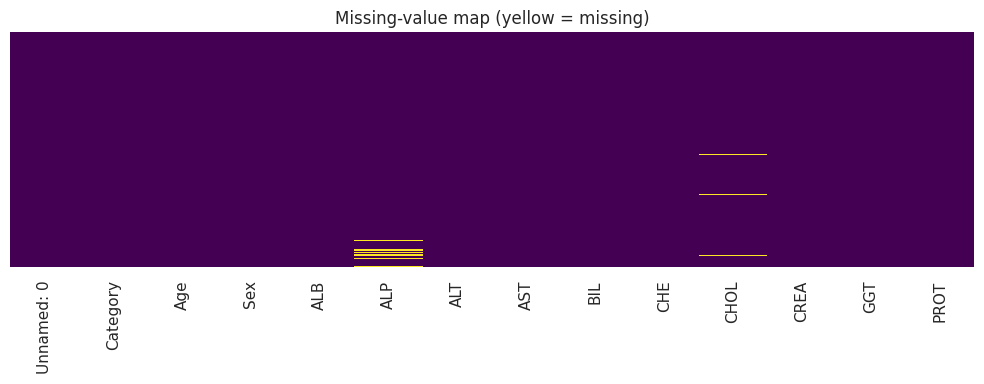

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis", ax=ax)
ax.set_title("Missing-value map (yellow = missing)")
save_fig("02_missing_value_map", fig)

### 2.6 Identify duplicate rows (ignoring the row-id column)

In [18]:
id_col = df.columns[0]                       # 'Unnamed: 0'
dup_mask = df.drop(columns=[id_col]).duplicated()
print(f"Duplicate rows found: {int(dup_mask.sum())}")
if dup_mask.any():
    print(df[dup_mask])

Duplicate rows found: 0


## PART 3 - DATA CLEANING & TYPE HANDLING

In [19]:
df = df_raw.copy()

### 3.1 Rename column(s)  (QP2 Q21): 'Unnamed: 0' -> 'Patient_ID'

In [20]:
df = df.rename(columns={df.columns[0]: "Patient_ID"})
print(list(df.columns))

['Patient_ID', 'Category', 'Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']


### 3.2 Identify columns stored with incorrect data types  (QP3 Q11)

In [21]:
print(df.dtypes)
print("\nFinding: 'Category' and 'Sex' are stored as text but are categorical; "
      "'Patient_ID' is only a row identifier.")

Patient_ID      int64
Category       object
Age             int64
Sex            object
ALB           float64
ALP           float64
ALT           float64
AST           float64
BIL           float64
CHE           float64
CHOL          float64
CREA          float64
GGT           float64
PROT          float64
dtype: object

Finding: 'Category' and 'Sex' are stored as text but are categorical; 'Patient_ID' is only a row identifier.


### 3.3 Convert character variables into categorical (factor)  (QP2 Q20, QP3 Q12)

In [22]:
df["Sex"] = df["Sex"].astype("category")
df["Category"] = pd.Categorical(df["Category"], categories=CAT_ORDER, ordered=True)
print(df[["Category", "Sex"]].dtypes)

Category    category
Sex         category
dtype: object


### 3.4 Convert text to lower / UPPER case  (QP3 Q13)

In [23]:
demo = df[["Category", "Sex"]].copy()
demo["Sex"] = demo["Sex"].astype(str).str.upper()
demo["Category"] = demo["Category"].astype(str).str.lower()
print("Levels of Sex (upper)     :", sorted(demo["Sex"].unique()))
print("Levels of Category (lower):", sorted(demo["Category"].unique()))
df["Sex"] = df["Sex"].astype(str).str.upper().astype("category")   # keep 'F'/'M' going forward

Levels of Sex (upper)     : ['F', 'M']
Levels of Category (lower): ['0=blood donor', '0s=suspect blood donor', '1=hepatitis', '2=fibrosis', '3=cirrhosis']


### 3.5 Mean imputation of numerical NAs  (QP2 Q13, QP3 Q6)

In [24]:
num_cols = df.select_dtypes("number").columns.drop("Patient_ID")
df_mean = df.copy()
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())
print("Remaining NAs after mean imputation:", int(df_mean[num_cols].isna().sum().sum()))

Remaining NAs after mean imputation: 0


### 3.6 Median imputation of numerical NAs  (QP2 Q14, QP3 Q7)

In [25]:
df_median = df.copy()
df_median[num_cols] = df_median[num_cols].fillna(df_median[num_cols].median())
print("Remaining NAs after median imputation:", int(df_median[num_cols].isna().sum().sum()))

Remaining NAs after median imputation: 0


### 3.7 Mode imputation of categorical NAs  (QP2 Q15, QP3 Q8)

In [26]:
df_mode = df.copy()
for c in ["Category", "Sex"]:
    mode_val = get_mode(df_mode[c])
    df_mode[c] = df_mode[c].fillna(mode_val)
    print(f"{c}: mode = {mode_val!r}; NAs left = {int(df_mode[c].isna().sum())}")

Category: mode = '0=Blood Donor'; NAs left = 0
Sex: mode = 'M'; NAs left = 0


### 3.8 Forward fill / backward fill / constant fill  (QP2 Q16-Q18; R: na.locf)

In [27]:
df_ffill = df.copy()
df_ffill[num_cols] = df_ffill[num_cols].ffill()
df_bfill = df.copy()
df_bfill[num_cols] = df_bfill[num_cols].bfill()
df_const = df.copy()
df_const[num_cols] = df_const[num_cols].fillna(0)
print("NAs after ffill :", int(df_ffill[num_cols].isna().sum().sum()))
print("NAs after bfill :", int(df_bfill[num_cols].isna().sum().sum()))
print("NAs after const :", int(df_const[num_cols].isna().sum().sum()))
print("(For ffill/bfill, leading/trailing NAs would need the constant fill - none here.)")

NAs after ffill : 0
NAs after bfill : 2
NAs after const : 0
(For ffill/bfill, leading/trailing NAs would need the constant fill - none here.)


### 3.9 Drop all rows that contain missing values (listwise deletion)  (QP2 Q12)

In [28]:
df_dropna = df.dropna()
print(f"Rows before: {len(df)} | after na.omit: {len(df_dropna)}")
print(df_dropna.head())

Rows before: 615 | after na.omit: 589
   Patient_ID       Category  Age Sex   ALB   ALP   ALT   AST   BIL    CHE  CHOL   CREA   GGT  PROT
0           1  0=Blood Donor   32   M  38.5  52.5   7.7  22.1   7.5   6.93  3.23  106.0  12.1  69.0
1           2  0=Blood Donor   32   M  38.5  70.3  18.0  24.7   3.9  11.17  4.80   74.0  15.6  76.5
2           3  0=Blood Donor   32   M  46.9  74.7  36.2  52.6   6.1   8.84  5.20   86.0  33.2  79.3
3           4  0=Blood Donor   32   M  43.2  52.0  30.6  22.6  18.9   7.33  4.74   80.0  33.8  75.7
4           5  0=Blood Donor   32   M  39.2  74.1  32.6  24.8   9.6   9.15  4.32   76.0  29.9  68.7


### 3.10 Remove duplicate rows  (QP2 Q19, QP3 Q10, QP10 Q3)

In [29]:
before = len(df)
df = df.drop_duplicates(subset=df.columns.drop("Patient_ID"))
print(f"Rows before: {before} | after: {len(df)}")

Rows before: 615 | after: 615


### 3.11 FINAL ANALYSIS DATASET: median-imputed (robust to the skewed lab values)

In [30]:
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df = df.set_index("Patient_ID")
print("Missing values remaining:", int(df.isna().sum().sum()))
print(df.dtypes)

Missing values remaining: 0
Category    category
Age            int64
Sex         category
ALB          float64
ALP          float64
ALT          float64
AST          float64
BIL          float64
CHE          float64
CHOL         float64
CREA         float64
GGT          float64
PROT         float64
dtype: object


### 3.12 Derived column  (QP2 Q22): AST/ALT ratio (De Ritis ratio) and ALB+ALP total

In [31]:
df["AST_ALT_ratio"] = df["AST"] / df["ALT"].replace(0, np.nan)
df["ALB_plus_ALP"] = df["ALB"] + df["ALP"]
print(df[["AST", "ALT", "AST_ALT_ratio", "ALB", "ALP", "ALB_plus_ALP"]].head())

             AST   ALT  AST_ALT_ratio   ALB   ALP  ALB_plus_ALP
Patient_ID                                                     
1           22.1   7.7       2.870130  38.5  52.5          91.0
2           24.7  18.0       1.372222  38.5  70.3         108.8
3           52.6  36.2       1.453039  46.9  74.7         121.6
4           22.6  30.6       0.738562  43.2  52.0          95.2
5           24.8  32.6       0.760736  39.2  74.1         113.3


### 3.13 Min, max, range, variance, SD, IQR of a numerical variable (ALB)  (QP2 Q24-Q28)

In [32]:
x = df["ALB"]
print(f"Min={x.min()}  Max={x.max()}  Range={x.max() - x.min():.2f}  "
      f"Var={x.var():.3f}  SD={x.std():.3f}  IQR={x.quantile(.75) - x.quantile(.25):.3f}")
print("\nIQR of every numeric column  (R: sapply(df, IQR)):")
print((df[NUM_COLS_LAB].quantile(.75) - df[NUM_COLS_LAB].quantile(.25)).round(3))

Min=14.9  Max=82.2  Range=67.30  Var=33.361  SD=5.776  IQR=6.400

IQR of every numeric column  (R: sapply(df, IQR)):
ALB      6.400
ALP     26.350
ALT     16.650
AST     11.300
BIL      5.900
CHE      2.655
CHOL     1.435
CREA    21.000
GGT     24.500
PROT     6.100
dtype: float64


### 3.14 Summary statistics of the cleaned dataset  (R: summary)

In [33]:
print(df.describe(include="all").T)

               count unique            top freq        mean        std       min       25%       50%       75%        max
Category         615      5  0=Blood Donor  533         NaN        NaN       NaN       NaN       NaN       NaN        NaN
Age            615.0    NaN            NaN  NaN    47.40813  10.055105      19.0      39.0      47.0      54.0       77.0
Sex              615      2              M  377         NaN        NaN       NaN       NaN       NaN       NaN        NaN
ALB            615.0    NaN            NaN  NaN   41.620732   5.775935      14.9      38.8     41.95      45.2       82.2
ALP            615.0    NaN            NaN  NaN   68.222927  25.646364      11.3     52.95      66.2      79.3      416.6
ALT            615.0    NaN            NaN  NaN   28.441951  25.449889       0.9      16.4      23.0     33.05      325.3
AST            615.0    NaN            NaN  NaN   34.786341   33.09069      10.6      21.6      25.9      32.9      324.0
BIL            615.0    

## PART 4 - DATA INTEGRATION & TRANSFORMATION  (QP1)

In [34]:
reg_no = REG_NO
base = df.reset_index()[["Patient_ID", "Age", "Sex", "ALT", "AST"]]
dataframe1 = base.iloc[0:10].copy()                    # patients   1-10 : demographics + enzymes
dataframe3 = base.iloc[10:20].copy()                   # patients  11-20 : same attributes
dataframe2 = df.reset_index().loc[5:14, ["Patient_ID", "Category"]].copy()   # patients 6-15 : diagnosis

### 4.1 Append (row-bind) dataframe1 and dataframe3   (R: rbind)

In [35]:
print(pd.concat([dataframe1, dataframe3], ignore_index=True))

    Patient_ID  Age Sex   ALT   AST
0            1   32   M   7.7  22.1
1            2   32   M  18.0  24.7
2            3   32   M  36.2  52.6
3            4   32   M  30.6  22.6
4            5   32   M  32.6  24.8
5            6   32   M  18.5  19.7
6            7   32   M  17.5  17.8
7            8   32   M  35.8  31.1
8            9   32   M  23.2  21.2
9           10   32   M  20.3  20.0
10          11   32   M  21.7  22.4
11          12   33   M  10.3  20.0
12          13   33   M  23.6  22.0
13          14   33   M  15.9  24.0
14          15   33   M  22.5  23.0
15          16   33   M  33.1  38.0
16          17   33   M  17.2  22.9
17          18   33   M  32.4  31.2
18          19   33   M  38.9  40.3
19          20   33   M  32.6  34.9


### 4.2 Concatenate column-wise where applicable   (R: cbind)

In [36]:
print(pd.concat([dataframe1.reset_index(drop=True),
                 dataframe2.reset_index(drop=True)[["Category"]]], axis=1))

   Patient_ID  Age Sex   ALT   AST       Category
0           1   32   M   7.7  22.1  0=Blood Donor
1           2   32   M  18.0  24.7  0=Blood Donor
2           3   32   M  36.2  52.6  0=Blood Donor
3           4   32   M  30.6  22.6  0=Blood Donor
4           5   32   M  32.6  24.8  0=Blood Donor
5           6   32   M  18.5  19.7  0=Blood Donor
6           7   32   M  17.5  17.8  0=Blood Donor
7           8   32   M  35.8  31.1  0=Blood Donor
8           9   32   M  23.2  21.2  0=Blood Donor
9          10   32   M  20.3  20.0  0=Blood Donor


### 4.3 Merge dataframe1 and dataframe2 on Patient_ID

In [37]:
print(dataframe1.merge(dataframe2, on="Patient_ID"))

   Patient_ID  Age Sex   ALT   AST       Category
0           6   32   M  18.5  19.7  0=Blood Donor
1           7   32   M  17.5  17.8  0=Blood Donor
2           8   32   M  35.8  31.1  0=Blood Donor
3           9   32   M  23.2  21.2  0=Blood Donor
4          10   32   M  20.3  20.0  0=Blood Donor


### 4.4 Inner / Left / Right / Full outer joins

In [38]:
for how in ["inner", "left", "right", "outer"]:
    print(f"\n--- {how.upper()} JOIN ---")
    print(dataframe1.merge(dataframe2, on="Patient_ID", how=how))


--- INNER JOIN ---
   Patient_ID  Age Sex   ALT   AST       Category
0           6   32   M  18.5  19.7  0=Blood Donor
1           7   32   M  17.5  17.8  0=Blood Donor
2           8   32   M  35.8  31.1  0=Blood Donor
3           9   32   M  23.2  21.2  0=Blood Donor
4          10   32   M  20.3  20.0  0=Blood Donor

--- LEFT JOIN ---
   Patient_ID  Age Sex   ALT   AST       Category
0           1   32   M   7.7  22.1            NaN
1           2   32   M  18.0  24.7            NaN
2           3   32   M  36.2  52.6            NaN
3           4   32   M  30.6  22.6            NaN
4           5   32   M  32.6  24.8            NaN
5           6   32   M  18.5  19.7  0=Blood Donor
6           7   32   M  17.5  17.8  0=Blood Donor
7           8   32   M  35.8  31.1  0=Blood Donor
8           9   32   M  23.2  21.2  0=Blood Donor
9          10   32   M  20.3  20.0  0=Blood Donor

--- RIGHT JOIN ---
   Patient_ID   Age  Sex   ALT   AST       Category
0           6  32.0    M  18.5  19.7  0

### 4.5 Numeric vector: first value = last 4 digits of the registration number

In [39]:
last4 = int("".join(ch for ch in reg_no if ch.isdigit())[-4:] or 0)
vec = np.array([last4, 15, 28, 40, 55, 70, 82, 95, 110, 125], dtype=float)
print("Vector:", vec)

Vector: [  0.  15.  28.  40.  55.  70.  82.  95. 110. 125.]


### 4.6 Min-max normalisation to [-3, +3], [-1, +1] and [0, 1]

In [40]:
def minmax(x, lo, hi):
    return lo + (x - x.min()) * (hi - lo) / (x.max() - x.min())
print("[-3, +3] :", np.round(minmax(vec, -3, 3), 4))
print("[-1, +1] :", np.round(minmax(vec, -1, 1), 4))
print("[ 0,  1] :", np.round(minmax(vec, 0, 1), 4))

[-3, +3] : [-3.    -2.28  -1.656 -1.08  -0.36   0.36   0.936  1.56   2.28   3.   ]
[-1, +1] : [-1.    -0.76  -0.552 -0.36  -0.12   0.12   0.312  0.52   0.76   1.   ]
[ 0,  1] : [0.    0.12  0.224 0.32  0.44  0.56  0.656 0.76  0.88  1.   ]


### 4.7 Z-score standardisation

In [41]:
print(np.round((vec - vec.mean()) / vec.std(ddof=1), 4))

[-1.4907 -1.1301 -0.8175 -0.529  -0.1683  0.1924  0.4809  0.7934  1.1541
  1.5148]


### 4.8 Decimal-scaling normalisation

In [42]:
j = len(str(int(np.abs(vec).max())))
print(f"j = {j}  ->  x / 10^{j}")
print(vec / 10 ** j)

j = 3  ->  x / 10^3
[0.    0.015 0.028 0.04  0.055 0.07  0.082 0.095 0.11  0.125]


### 4.9 The same transforms on a real column (ALT): min-max and z-score

In [43]:
alt = df["ALT"]
print(pd.DataFrame({"ALT": alt, "ALT_minmax": minmax(alt, 0, 1),
                    "ALT_zscore": (alt - alt.mean()) / alt.std()}).head())

             ALT  ALT_minmax  ALT_zscore
Patient_ID                              
1            7.7    0.020962   -0.815011
2           18.0    0.052713   -0.410295
3           36.2    0.108816    0.304836
4           30.6    0.091554    0.084796
5           32.6    0.097719    0.163382


## PART 5 - OUTLIER ANALYSIS

In [44]:
num = df[NUM_COLS_LAB + ["Age"]]

### 5.1 Detect outliers using boxplots (all numeric variables)

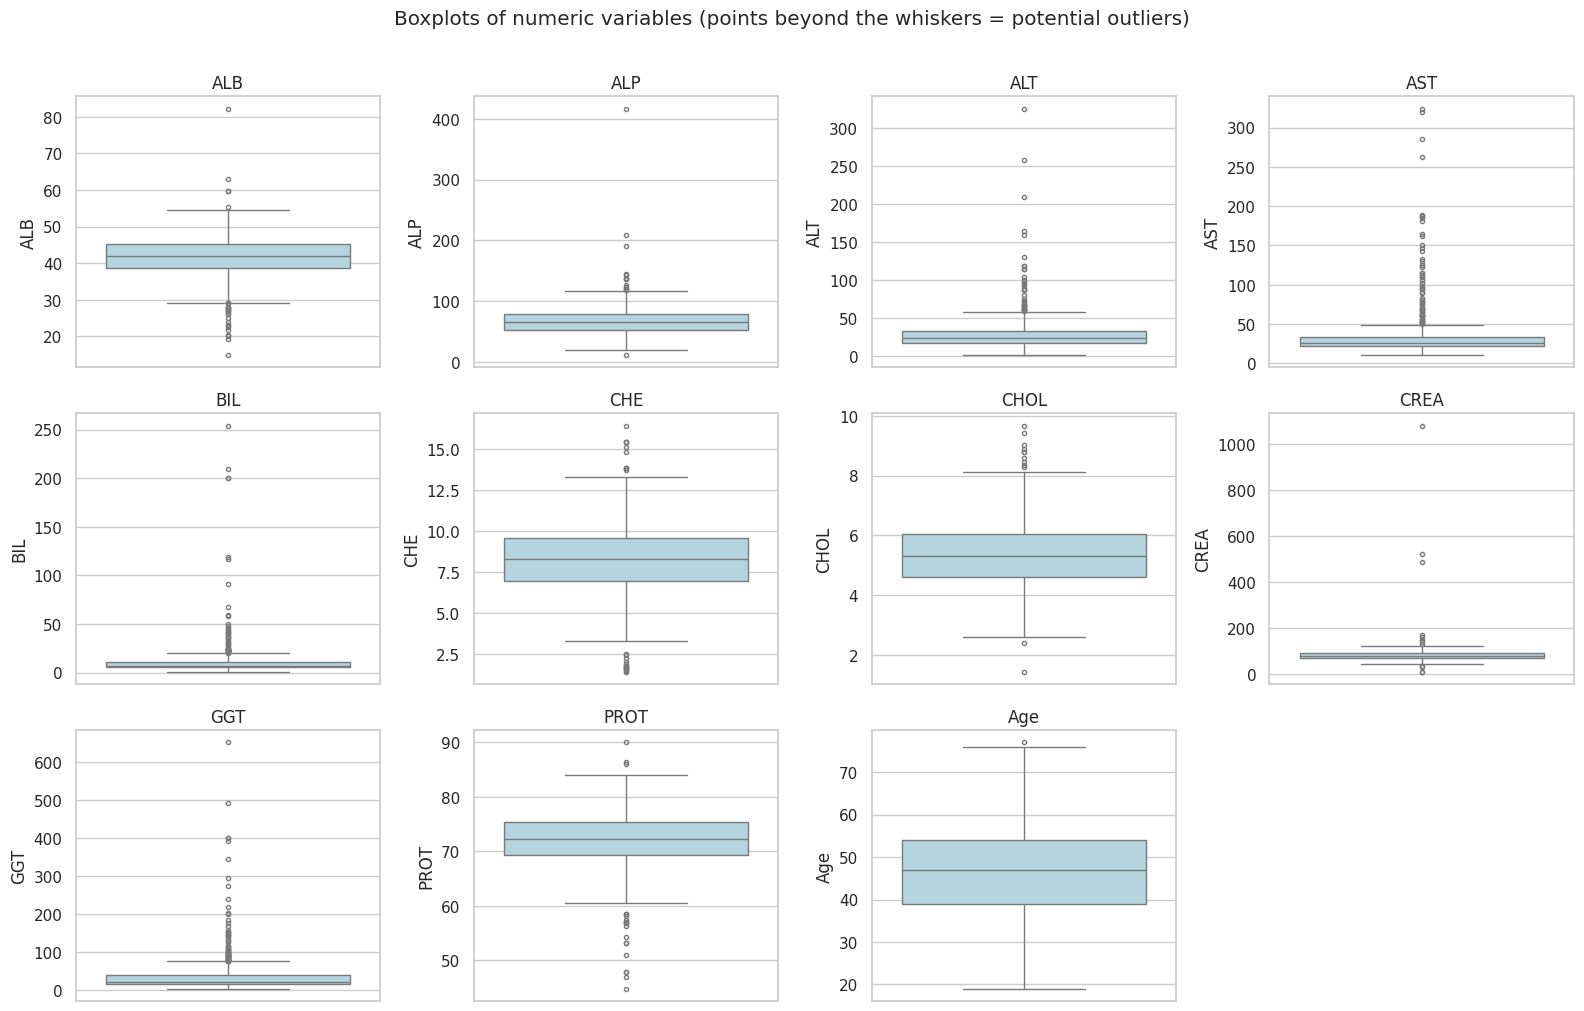

In [45]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), num.columns):
    sns.boxplot(y=num[col], ax=ax, color="lightblue", fliersize=3)
    ax.set_title(col)
for ax in axes.ravel()[len(num.columns):]:
    ax.set_visible(False)
fig.suptitle("Boxplots of numeric variables (points beyond the whiskers = potential outliers)", y=1.01)
save_fig("05_boxplots_all_numeric", fig)

### 5.2 IQR method - outlier counts and fences for every numeric column

In [46]:
rows = []
for col in num.columns:
    q1, q3, iqr, lo, hi = iqr_bounds(num[col])
    n_out = int(((num[col] < lo) | (num[col] > hi)).sum())
    _, _, _, elo, ehi = iqr_bounds(num[col], k=3)
    n_ext = int(((num[col] < elo) | (num[col] > ehi)).sum())
    rows.append([col, q1, q3, iqr, lo, hi, n_out, n_ext])
out_tbl = pd.DataFrame(rows, columns=["Variable", "Q1", "Q3", "IQR", "Lower(1.5)",
                                      "Upper(1.5)", "Outliers", "Extreme(3xIQR)"])
print(out_tbl.round(3).to_string(index=False))
print(f"\nTotal IQR outliers flagged: {int(out_tbl['Outliers'].sum())}")

Variable     Q1     Q3    IQR  Lower(1.5)  Upper(1.5)  Outliers  Extreme(3xIQR)
     ALB 38.800 45.200  6.400      29.200      54.800        27               3
     ALP 52.950 79.300 26.350      13.425     118.825        14               3
     ALT 16.400 33.050 16.650      -8.575      58.025        36              19
     AST 21.600 32.900 11.300       4.650      49.850        64              45
     BIL  5.300 11.200  5.900      -3.550      20.050        47              26
     CHE  6.935  9.590  2.655       2.953      13.572        24               0
    CHOL  4.620  6.055  1.435       2.468       8.208        12               0
    CREA 67.000 88.000 21.000      35.500     119.500        12               5
     GGT 15.700 40.200 24.500     -21.050      76.950        65              29
    PROT 69.300 75.400  6.100      60.150      84.550        20               4
     Age 39.000 54.000 15.000      16.500      76.500         1               0

Total IQR outliers flagged: 322


### 5.3 Detailed worked example on ALT  (QP3 Q15)

In [47]:
q1, q3, iqr, lo, hi = iqr_bounds(df["ALT"])
alt_out = df["ALT"][(df["ALT"] < lo) | (df["ALT"] > hi)]
print(f"Q1={q1:.2f}  Q3={q3:.2f}  IQR={iqr:.2f}  lower={lo:.2f}  upper={hi:.2f}")
print(f"Total outliers detected in ALT: {len(alt_out)}")

Q1=16.40  Q3=33.05  IQR=16.65  lower=-8.57  upper=58.02
Total outliers detected in ALT: 36


### 5.4 Remove EXTREME outliers (beyond Q1-3*IQR / Q3+3*IQR) on ALT  (QP3 Q16)

Extreme fences: [-33.55, 83.00]
Rows before: 615 | after: 596 | removed: 19
NOTE: extreme values mostly belong to hepatitis/cirrhosis patients (real signal), so the FULL dataset is kept for the rest of the analysis.


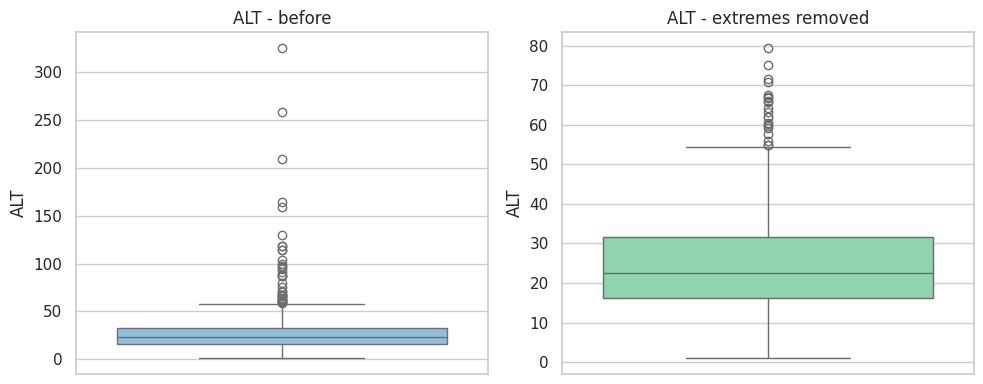

In [48]:
_, _, _, elo, ehi = iqr_bounds(df["ALT"], k=3)
df_no_ext = df[(df["ALT"] >= elo) & (df["ALT"] <= ehi)]
print(f"Extreme fences: [{elo:.2f}, {ehi:.2f}]")
print(f"Rows before: {len(df)} | after: {len(df_no_ext)} | removed: {len(df) - len(df_no_ext)}")
print("NOTE: extreme values mostly belong to hepatitis/cirrhosis patients (real signal), "
      "so the FULL dataset is kept for the rest of the analysis.")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df["ALT"], ax=axes[0], color="#85C1E9"); axes[0].set_title("ALT - before")
sns.boxplot(y=df_no_ext["ALT"], ax=axes[1], color="#82E0AA"); axes[1].set_title("ALT - extremes removed")
save_fig("05_alt_before_after_extreme_removal", fig)

## PART 6 - UNIVARIATE ANALYSIS : NUMERICAL VARIABLES

In [49]:
num_cols = ["Age"] + NUM_COLS_LAB

### 6.1 Full descriptive-statistics table (QP7 Q2-Q3)

In [50]:
desc = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Min": df[num_cols].min(),
    "Max": df[num_cols].max(),
    "Range": df[num_cols].max() - df[num_cols].min(),
    "Variance": df[num_cols].var(),
    "Std.Dev": df[num_cols].std(),
    "IQR": df[num_cols].quantile(.75) - df[num_cols].quantile(.25),
    "Skewness": df[num_cols].apply(skewness_e1071),
    "Kurtosis": df[num_cols].apply(kurtosis_e1071),
}).round(4)
desc.index.name = "Variable"
print(desc)
desc.to_csv(OUT_DIR / "06_descriptive_statistics.csv")

             Mean  Median    Min      Max    Range   Variance  Std.Dev     IQR  Skewness  Kurtosis
Variable                                                                                          
Age       47.4081   47.00  19.00    77.00    58.00   101.1051  10.0551  15.000    0.2658   -0.4015
ALB       41.6207   41.95  14.90    82.20    67.30    33.3614   5.7759   6.400   -0.1763    5.9104
ALP       68.2229   66.20  11.30   416.60   405.30   657.7360  25.6464  26.350    4.7070   56.0674
ALT       28.4420   23.00   0.90   325.30   324.40   647.6968  25.4499  16.650    5.4841   46.6560
AST       34.7863   25.90  10.60   324.00   313.40  1094.9938  33.0907  11.300    4.9163   30.4677
BIL       11.3967    7.30   0.80   254.00   253.20   387.0328  19.6731   5.900    8.3446   82.2244
CHE        8.1966    8.26   1.42    16.41    14.99     4.8649   2.2057   2.655   -0.1097    1.2804
CHOL       5.3670    5.30   1.43     9.67     8.24     1.2623   1.1235   1.435    0.3800    0.7281
CREA      

### 6.2 Histogram of a numerical variable + interpretation (QP3 Q17)

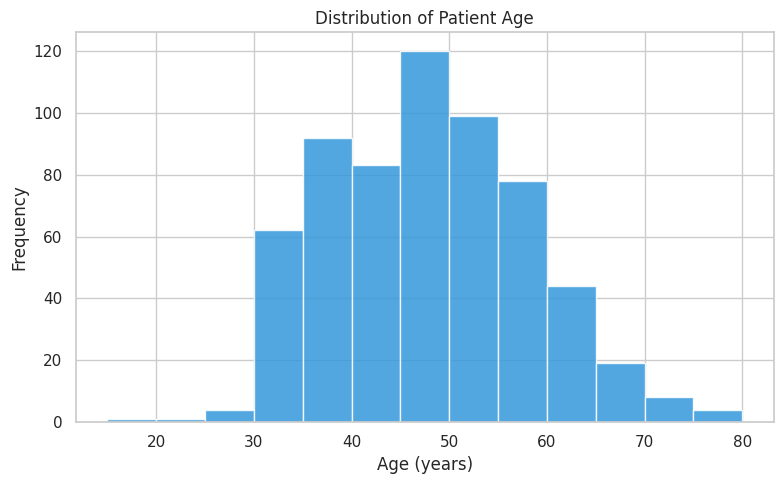

Interpretation: Age is roughly bell-shaped (skewness=0.27), centred near 47 years; most patients are 30-60.


In [51]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["Age"], bins=range(15, 85, 5), color="#3498DB", edgecolor="white", alpha=.85)
ax.set(title="Distribution of Patient Age", xlabel="Age (years)", ylabel="Frequency")
save_fig("06_hist_age", fig)
print(f"Interpretation: Age is roughly bell-shaped (skewness={skewness_e1071(df['Age']):.2f}), "
      f"centred near {df['Age'].median():.0f} years; most patients are 30-60.")

### 6.3 Histogram with a density (KDE) curve (QP3 Q18)

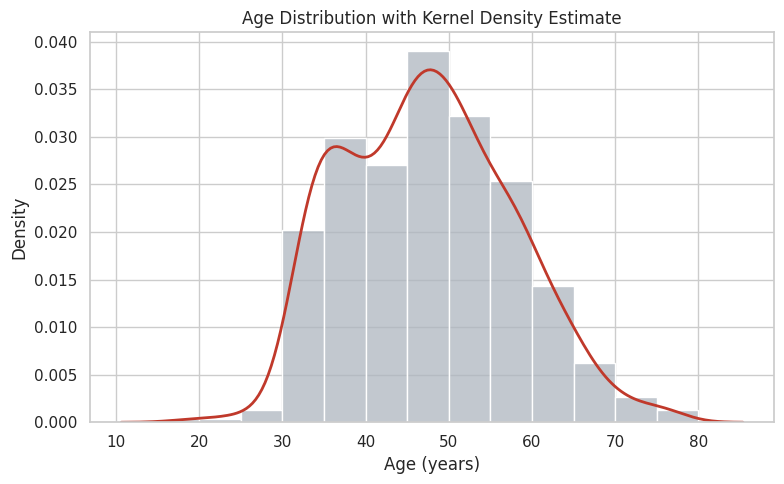

In [52]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["Age"], bins=range(15, 85, 5), stat="density", color="#AEB6BF", ax=ax)
sns.kdeplot(df["Age"], color="#C0392B", linewidth=2, ax=ax)
ax.set(title="Age Distribution with Kernel Density Estimate", xlabel="Age (years)", ylabel="Density")
save_fig("06_hist_kde_age", fig)

### 6.4 Frequency distribution table with bin intervals + histogram & box plot (QP7 Q5)

          Frequency  Relative freq
Age                               
[15, 20)          1         0.0016
[20, 25)          1         0.0016
[25, 30)          4         0.0065
[30, 35)         62         0.1008
[35, 40)         92         0.1496
[40, 45)         83         0.1350
[45, 50)        120         0.1951
[50, 55)         99         0.1610
[55, 60)         78         0.1268
[60, 65)         44         0.0715
[65, 70)         19         0.0309
[70, 75)          8         0.0130
[75, 80)          4         0.0065


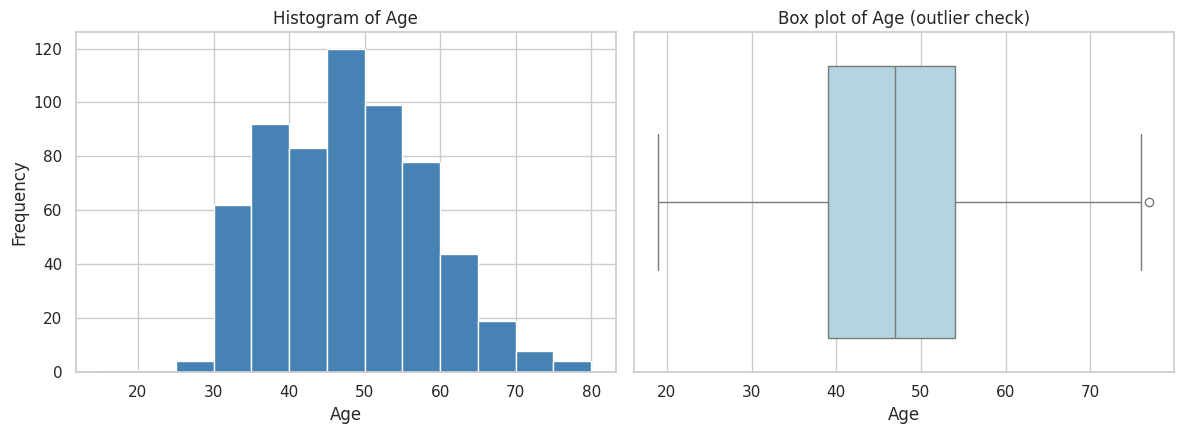

In [53]:
bins = np.arange(df["Age"].min() // 5 * 5, df["Age"].max() + 6, 5)
age_bins = pd.cut(df["Age"], bins=bins, right=False)
freq = age_bins.value_counts().sort_index()
print(pd.DataFrame({"Frequency": freq, "Relative freq": (freq / freq.sum()).round(4)}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(df["Age"], bins=bins, color="steelblue", edgecolor="white")
axes[0].set(title="Histogram of Age", xlabel="Age", ylabel="Frequency")
sns.boxplot(x=df["Age"], ax=axes[1], color="lightblue")
axes[1].set(title="Box plot of Age (outlier check)", xlabel="Age")
save_fig("06_age_histogram_and_boxplot", fig)

### 6.5 Violin plot of a numerical variable (QP3 Q19)

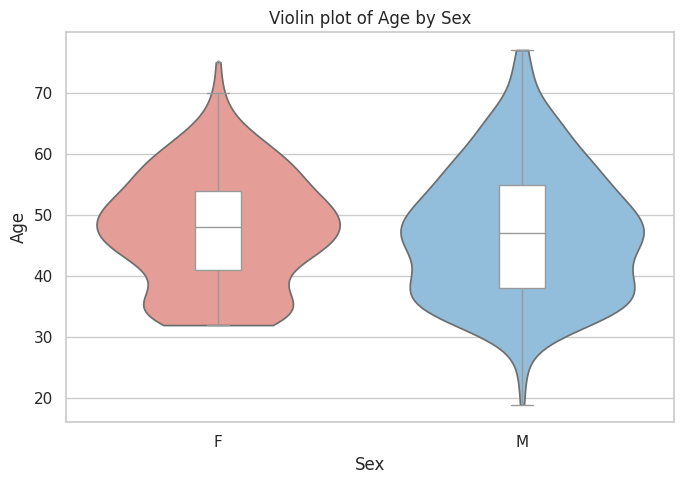

In [54]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.violinplot(data=df, x="Sex", y="Age", hue="Sex", palette={"F": "#F1948A", "M": "#85C1E9"},
               inner=None, cut=0, legend=False, ax=ax)
sns.boxplot(data=df, x="Sex", y="Age", width=.15, color="white", fliersize=2, ax=ax)
ax.set_title("Violin plot of Age by Sex")
save_fig("06_violin_age_by_sex", fig)

### 6.6 Dot plot for a small numerical dataset - first 30 patients (QP3 Q20)

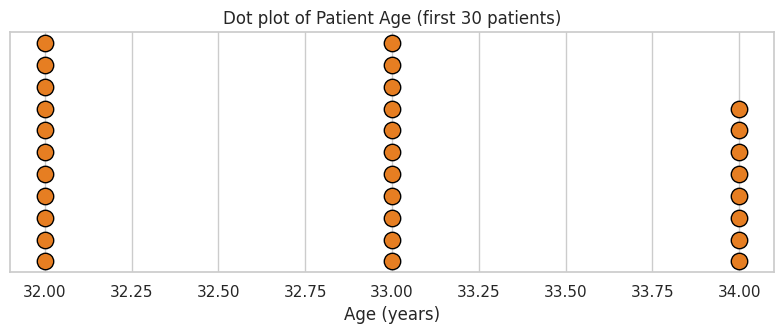

In [55]:
small = df["Age"].head(30)
counts = small.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.5))
for age, n in counts.items():
    ax.scatter([age] * n, range(1, n + 1), s=140, color="#E67E22", edgecolor="black")
ax.set(title="Dot plot of Patient Age (first 30 patients)", xlabel="Age (years)")
ax.set_yticks([])
save_fig("06_dotplot_age_30", fig)

### 6.7 Density plot of a variable split by group - CHOL by Sex (QP3 Q29)

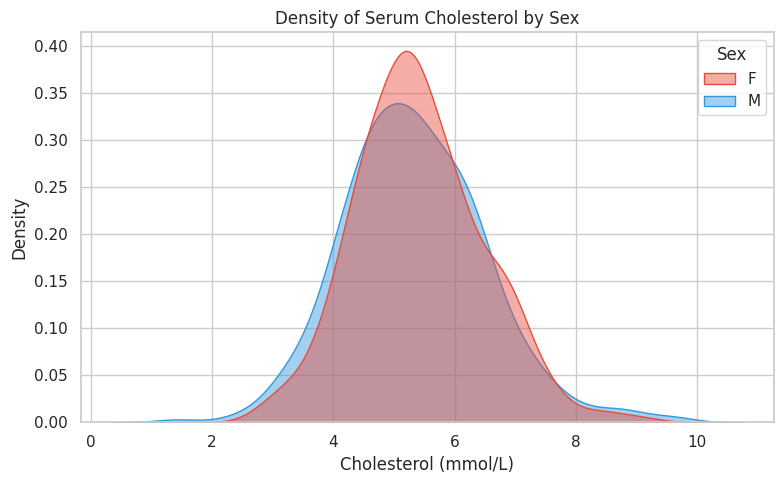

In [56]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=df, x="CHOL", hue="Sex", fill=True, alpha=.45, common_norm=False,
            palette={"F": "#E74C3C", "M": "#3498DB"}, ax=ax)
ax.set(title="Density of Serum Cholesterol by Sex", xlabel="Cholesterol (mmol/L)")
save_fig("06_density_chol_by_sex", fig)

### 6.8 Distribution of EVERY numeric variable (histogram + KDE grid)

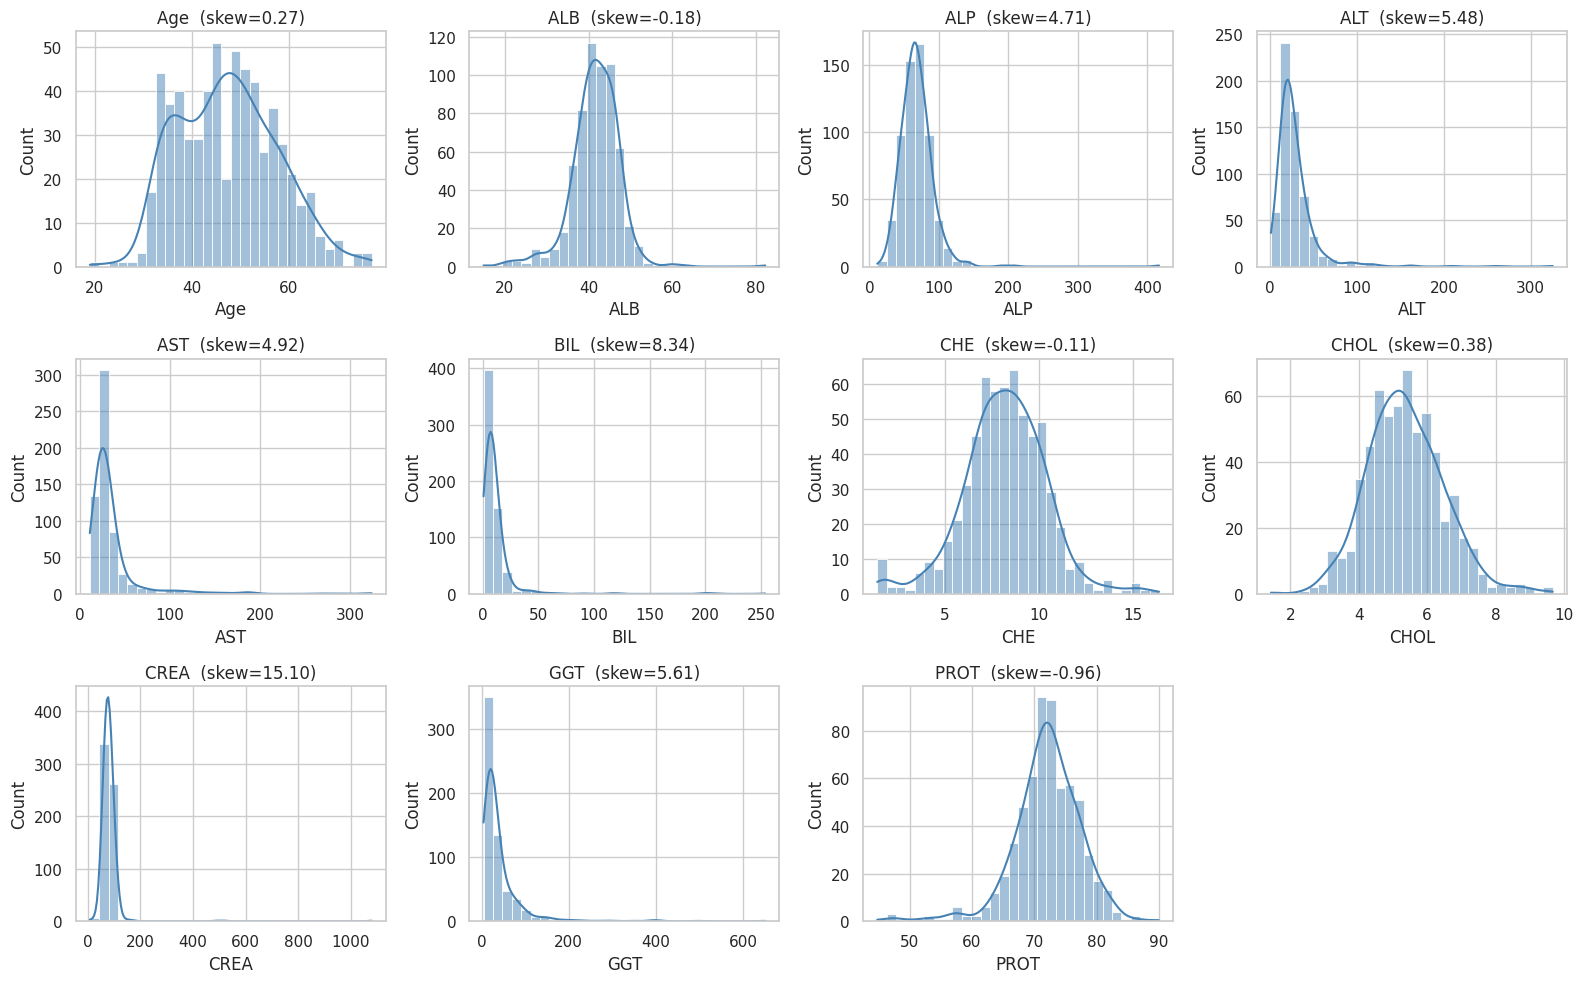

In [57]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, bins=30, color="steelblue", ax=ax)
    ax.set_title(f"{col}  (skew={desc.loc[col, 'Skewness']:.2f})")
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
save_fig("06_all_numeric_distributions", fig)

### 6.9 Facets: one variable across groups - Age by Category (QP3 Q30)

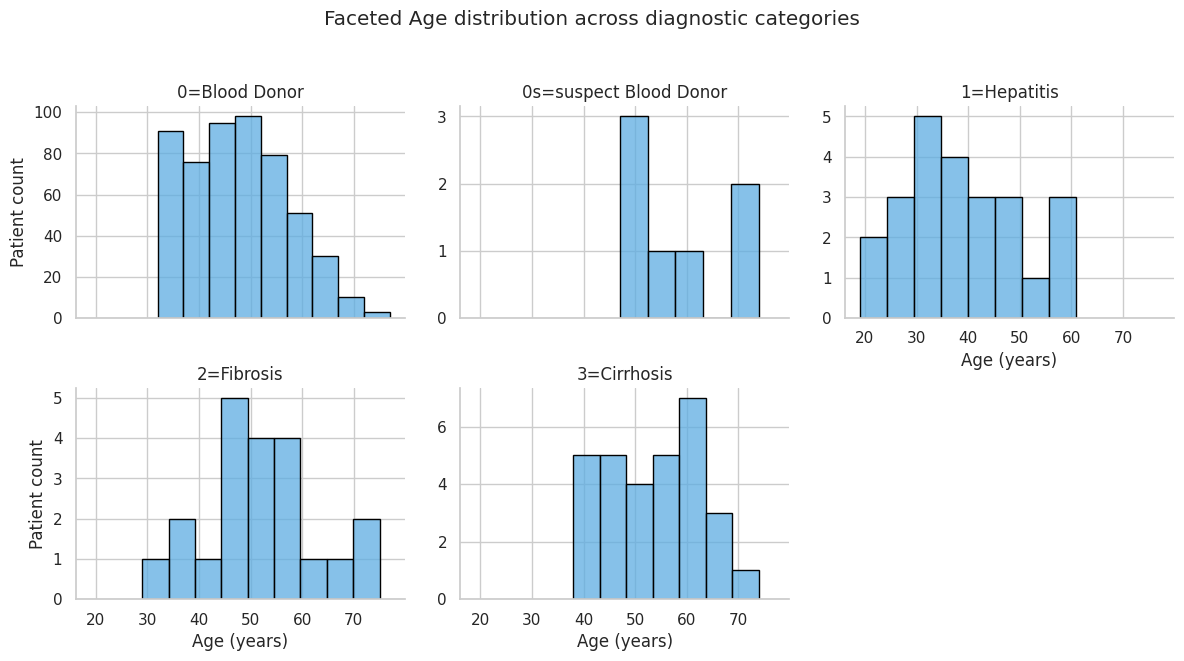

Interpretation: Blood donors are mostly 30-60; hepatitis/fibrosis/cirrhosis groups are small and shifted slightly older; the suspect-donor group (n=7) is too small to read a shape.


In [58]:
g = sns.FacetGrid(df.reset_index(), col="Category", col_wrap=3, sharey=False, height=3.2, aspect=1.25)
g.map_dataframe(sns.histplot, x="Age", binwidth=5, color="#5DADE2", edgecolor="black")
g.set_titles("{col_name}"); g.set_axis_labels("Age (years)", "Patient count")
g.figure.suptitle("Faceted Age distribution across diagnostic categories", y=1.03)
save_fig("06_facet_age_by_category", g.figure)
print("Interpretation: Blood donors are mostly 30-60; hepatitis/fibrosis/cirrhosis groups are small "
      "and shifted slightly older; the suspect-donor group (n=7) is too small to read a shape.")

## PART 7 - UNIVARIATE ANALYSIS : CATEGORICAL VARIABLES

### 7.1 Frequency, relative frequency, proportion and percentage (QP3 Q21-22, QP7 Q4)

In [59]:
freq = df["Category"].value_counts().reindex(CAT_ORDER)
tbl = pd.DataFrame({"Frequency": freq,
                    "Proportion": (freq / freq.sum()).round(4),
                    "Percentage": (freq / freq.sum() * 100).round(2)})
print(tbl)
print("\nSex frequency:"); print(df["Sex"].value_counts())

                        Frequency  Proportion  Percentage
Category                                                 
0=Blood Donor                 533      0.8667       86.67
0s=suspect Blood Donor          7      0.0114        1.14
1=Hepatitis                    24      0.0390        3.90
2=Fibrosis                     21      0.0341        3.41
3=Cirrhosis                    30      0.0488        4.88

Sex frequency:
Sex
M    377
F    238
Name: count, dtype: int64


### 7.2 Bar chart of frequencies (QP3 Q23)

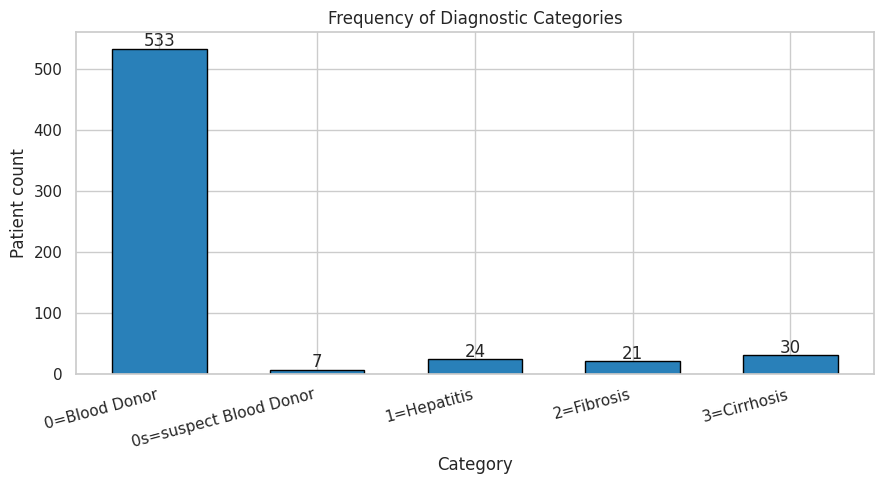

In [60]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(freq.index, freq.values, color="#2980B9", edgecolor="black", width=.6)
for i, v in enumerate(freq.values):
    ax.text(i, v + 4, str(v), ha="center")
ax.set(title="Frequency of Diagnostic Categories", xlabel="Category", ylabel="Patient count")
rotate_xticks(ax, 15)
save_fig("07_bar_frequency", fig)

### 7.3 Horizontal bar chart (QP3 Q24)

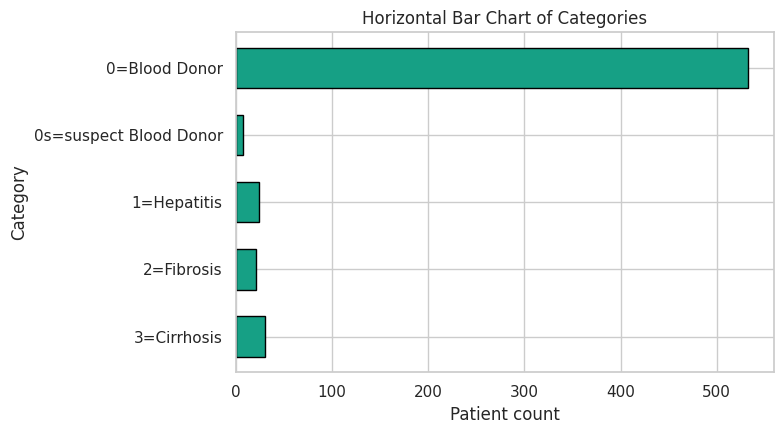

In [61]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(freq.index[::-1], freq.values[::-1], color="#16A085", edgecolor="black", height=.6)
ax.set(title="Horizontal Bar Chart of Categories", xlabel="Patient count", ylabel="Category")
save_fig("07_barh_frequency", fig)

### 7.4 Percentage bar chart (QP3 Q25)

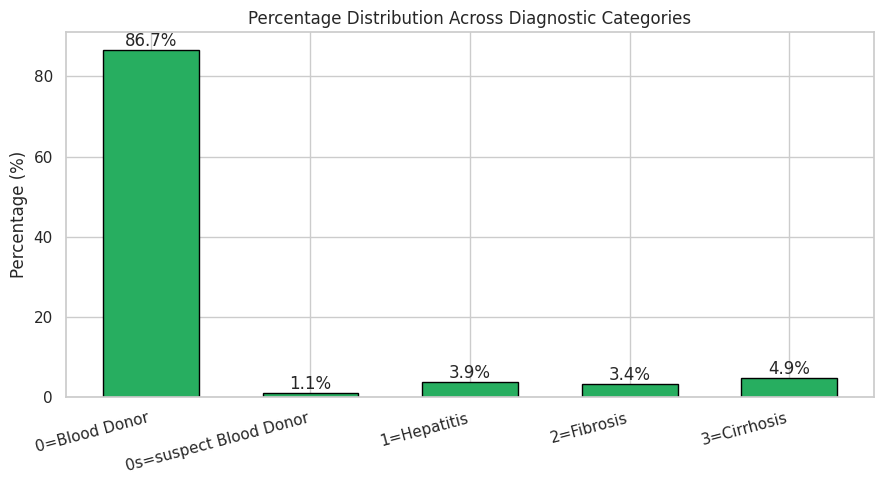

In [62]:
fig, ax = plt.subplots(figsize=(9, 5))
pct = freq / freq.sum() * 100
ax.bar(pct.index, pct.values, color="#27AE60", edgecolor="black", width=.6)
for i, v in enumerate(pct.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set(title="Percentage Distribution Across Diagnostic Categories", ylabel="Percentage (%)")
rotate_xticks(ax, 15)
save_fig("07_bar_percentage", fig)

### 7.5 Pie charts: Sex (small number of categories) and Category (QP3 Q26, QP7 Q4)

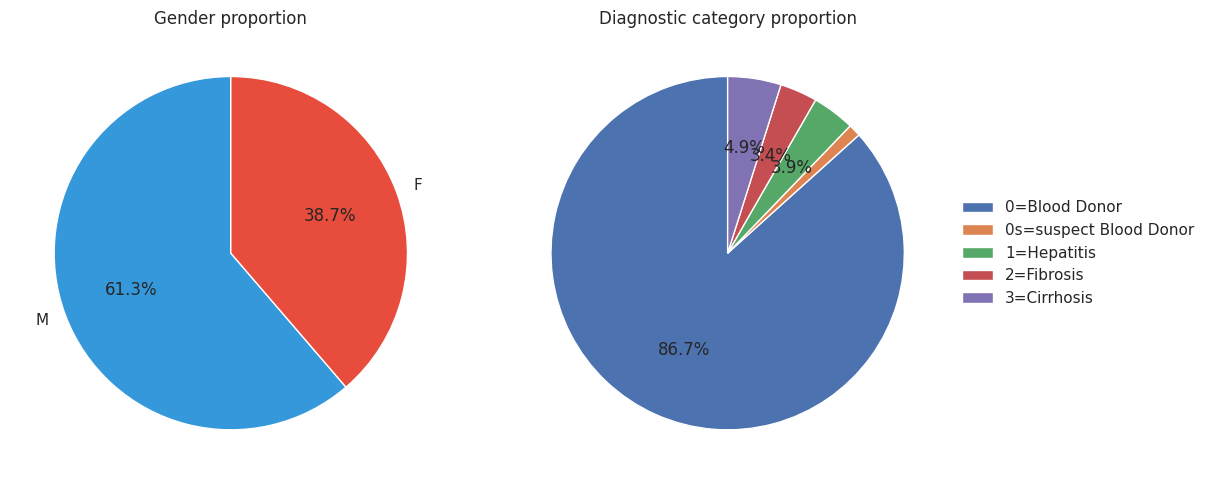

In [63]:
sex_counts = df["Sex"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].pie(sex_counts, labels=sex_counts.index, autopct="%1.1f%%", startangle=90,
            colors=["#3498DB", "#E74C3C"], wedgeprops={"edgecolor": "white"})
axes[0].set_title("Gender proportion")
axes[1].pie(freq, labels=None, autopct=lambda p: f"{p:.1f}%" if p > 2 else "", startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].legend(freq.index, loc="center left", bbox_to_anchor=(1, .5), frameon=False)
axes[1].set_title("Diagnostic category proportion")
save_fig("07_pie_sex_and_category", fig)

### 7.6 Lollipop chart (QP3 Q27)

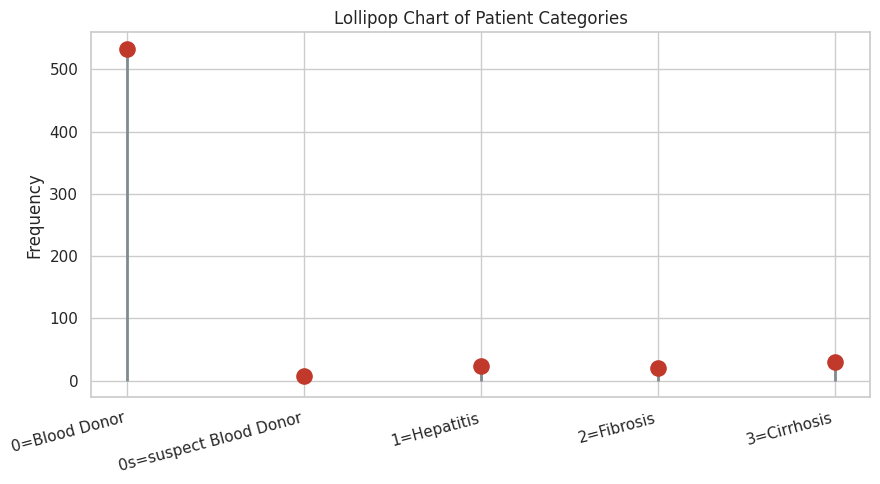

In [64]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.vlines(freq.index, 0, freq.values, color="#7F8C8D", linewidth=2)
ax.scatter(freq.index, freq.values, color="#C0392B", s=120, zorder=3)
ax.set(title="Lollipop Chart of Patient Categories", ylabel="Frequency")
rotate_xticks(ax, 15)
save_fig("07_lollipop", fig)

### 7.7 Cleveland dot chart (sorted) (QP3 Q28)

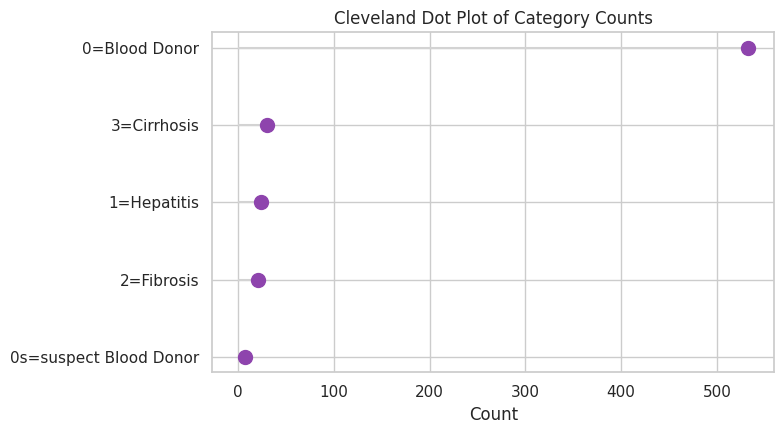

In [65]:
srt = freq.sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hlines(srt.index, 0, srt.values, color="lightgrey")
ax.scatter(srt.values, srt.index, color="#8E44AD", s=100, zorder=3)
ax.set(title="Cleveland Dot Plot of Category Counts", xlabel="Count")
save_fig("07_cleveland_dotplot", fig)

## PART 8 - BIVARIATE ANALYSIS

In [66]:
d = df.reset_index()

### 8.1 Contingency table Category x Sex + row / column / overall proportions (QP4 Q2, QP7 Q6)

In [67]:
ct = pd.crosstab(d["Category"], d["Sex"])
print(ct)
print("\nRow proportions (each category sums to 1):");  print(pd.crosstab(d["Category"], d["Sex"], normalize="index").round(4))
print("\nColumn proportions (each sex sums to 1):");    print(pd.crosstab(d["Category"], d["Sex"], normalize="columns").round(4))
print("\nOverall proportions:");                        print(pd.crosstab(d["Category"], d["Sex"], normalize="all").round(4))
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"\nChi-square test of independence: chi2={chi2:.3f}, dof={dof}, p-value={p:.4f}")

Sex                       F    M
Category                        
0=Blood Donor           215  318
0s=suspect Blood Donor    1    6
1=Hepatitis               4   20
2=Fibrosis                8   13
3=Cirrhosis              10   20

Row proportions (each category sums to 1):
Sex                          F       M
Category                              
0=Blood Donor           0.4034  0.5966
0s=suspect Blood Donor  0.1429  0.8571
1=Hepatitis             0.1667  0.8333
2=Fibrosis              0.3810  0.6190
3=Cirrhosis             0.3333  0.6667

Column proportions (each sex sums to 1):
Sex                          F       M
Category                              
0=Blood Donor           0.9034  0.8435
0s=suspect Blood Donor  0.0042  0.0159
1=Hepatitis             0.0168  0.0531
2=Fibrosis              0.0336  0.0345
3=Cirrhosis             0.0420  0.0531

Overall proportions:
Sex                          F       M
Category                              
0=Blood Donor           0.3496  0.517

### 8.2 Stacked bar plot - pandas/matplotlib ('Base R' equivalent) and seaborn ('ggplot2' equivalent)

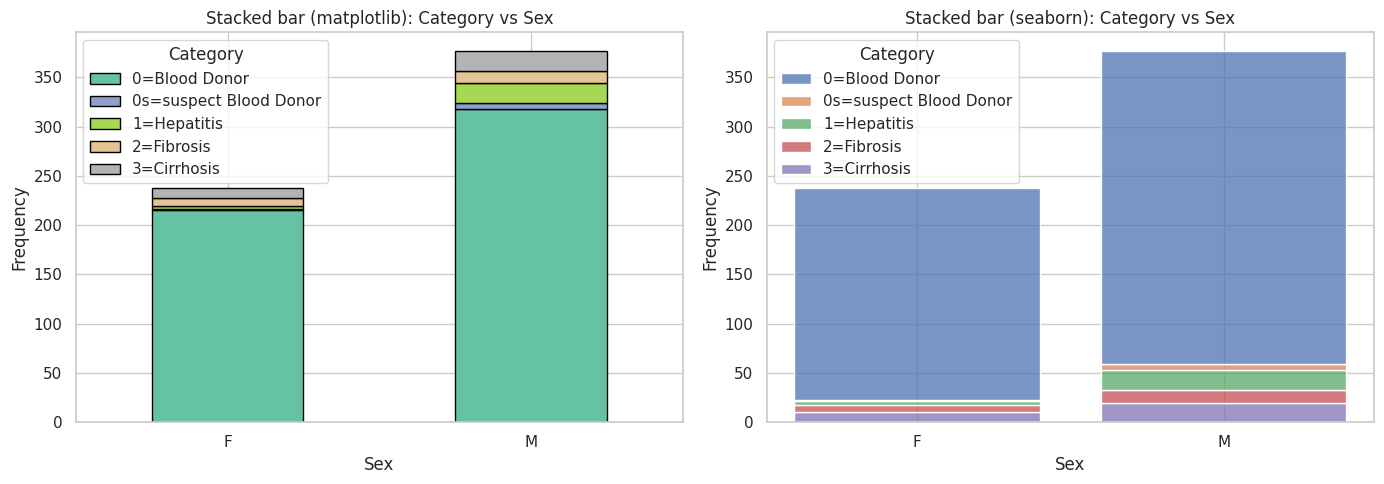

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ct.T.plot(kind="bar", stacked=True, ax=axes[0], edgecolor="black", colormap="Set2")
axes[0].set(title="Stacked bar (matplotlib): Category vs Sex", xlabel="Sex", ylabel="Frequency")
plt.setp(axes[0].get_xticklabels(), rotation=0)
sns.histplot(data=d, x="Sex", hue="Category", multiple="stack", shrink=.8, hue_order=CAT_ORDER, ax=axes[1])
axes[1].set(title="Stacked bar (seaborn): Category vs Sex", ylabel="Frequency")
save_fig("08_stacked_bar_category_sex", fig)

### 8.3 Grouped / side-by-side bar plot (QP4 Q3, QP7 Q7)

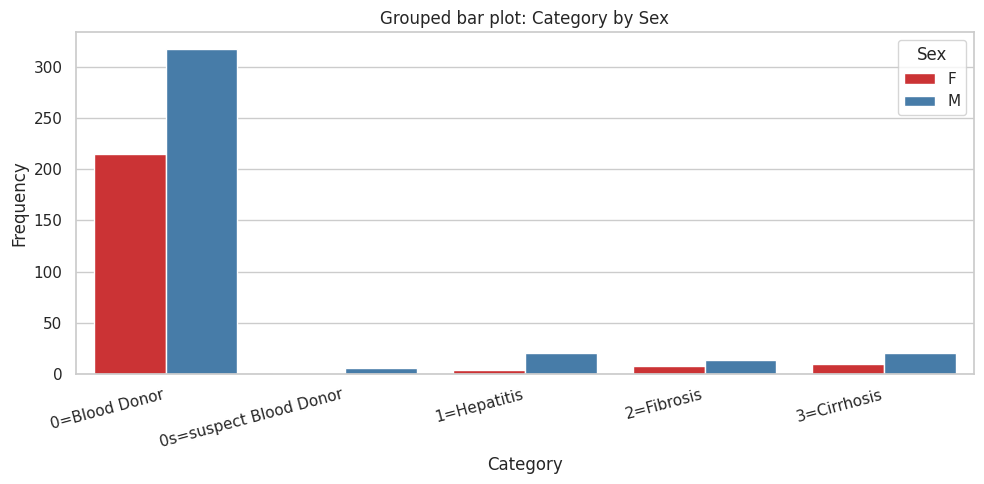

In [69]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=d, x="Category", hue="Sex", order=CAT_ORDER, palette="Set1", ax=ax)
ax.set(title="Grouped bar plot: Category by Sex", ylabel="Frequency")
rotate_xticks(ax, 15)
save_fig("08_grouped_bar_category_sex", fig)

### 8.4 Scatter plot of two numerical variables: Age vs ALT (QP4 Q4)

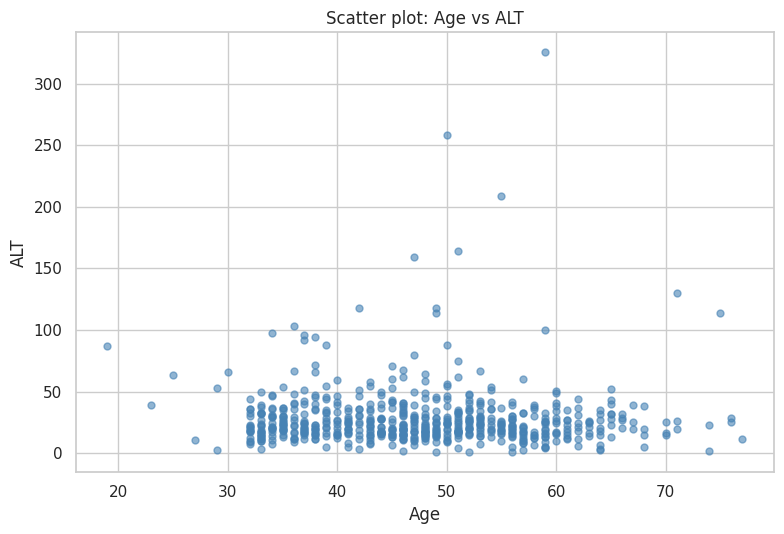

Pearson r(Age, ALT) = -0.0057


In [70]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(d["Age"], d["ALT"], s=25, alpha=.6, color="steelblue")
ax.set(title="Scatter plot: Age vs ALT", xlabel="Age", ylabel="ALT")
save_fig("08_scatter_age_alt", fig)
print(f"Pearson r(Age, ALT) = {d['Age'].corr(d['ALT']):.4f}")

### 8.5 Line plot: mean ALT and mean ALB by Age (trend) (QP4 Q5)

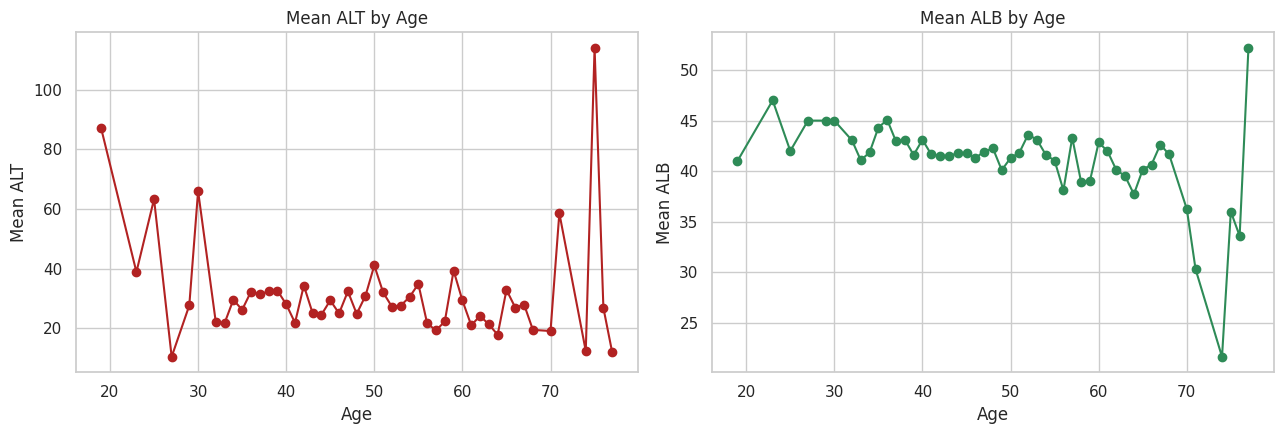

In [71]:
trend = d.groupby("Age")[["ALT", "ALB"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(trend.index, trend["ALT"], marker="o", color="firebrick")
axes[0].set(title="Mean ALT by Age", xlabel="Age", ylabel="Mean ALT")
axes[1].plot(trend.index, trend["ALB"], marker="o", color="seagreen")
axes[1].set(title="Mean ALB by Age", xlabel="Age", ylabel="Mean ALB")
save_fig("08_line_trend_by_age", fig)

### 8.6 Pearson & Spearman correlation + scatter with fitted regression line: ALT vs AST (QP7 Q10)

Pearson  r(ALT, AST) = 0.2733
Spearman rho(ALT, AST) = 0.4965


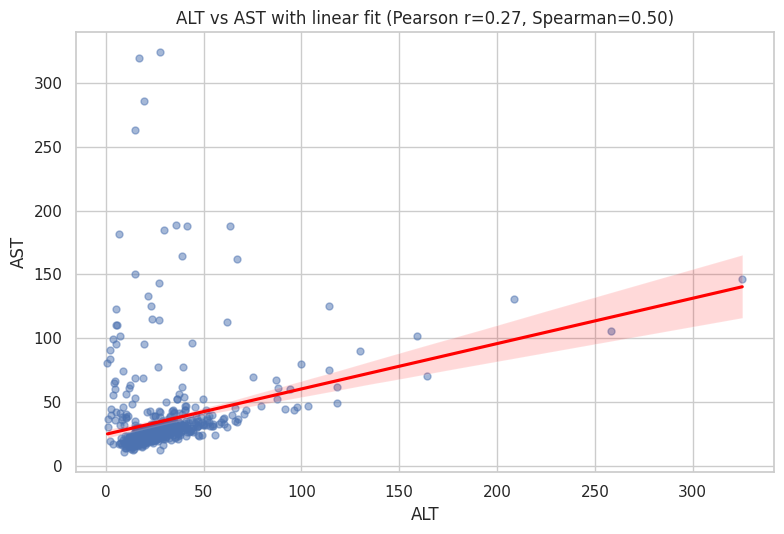

In [72]:
pear = d["ALT"].corr(d["AST"], method="pearson")
spear = d["ALT"].corr(d["AST"], method="spearman")
print(f"Pearson  r(ALT, AST) = {pear:.4f}\nSpearman rho(ALT, AST) = {spear:.4f}")
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.regplot(data=d, x="ALT", y="AST", scatter_kws={"alpha": .5, "s": 25}, line_kws={"color": "red"}, ax=ax)
ax.set_title(f"ALT vs AST with linear fit (Pearson r={pear:.2f}, Spearman={spear:.2f})")
save_fig("08_scatter_alt_ast_regression", fig)

### 8.7 Group statistics: mean / median / SD of ALT per Category via groupby-agg (QP7 Q8)

In [73]:
grp = d.groupby("Category", observed=True)["ALT"].agg(["count", "mean", "median", "std", "min", "max"]).round(3)
print(grp)

                        count     mean  median      std  min    max
Category                                                           
0=Blood Donor             533   26.632   23.10   14.501  2.5  118.1
0s=suspect Blood Donor      7  102.114   49.20  119.837  9.5  325.3
1=Hepatitis                24   26.737   18.30   22.112  3.8   87.0
2=Fibrosis                 21   59.600   34.00   66.697  2.4  258.0
3=Cirrhosis                30   22.970    5.65   36.361  0.9  159.0


### 8.8 Bar chart comparing the mean values of two variables (ALT vs AST) across categories (QP4 Q7)

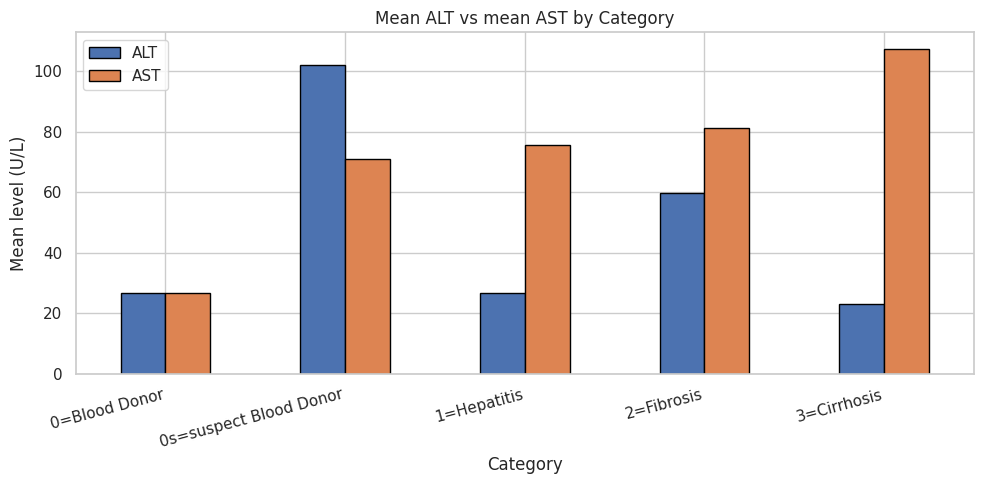

In [74]:
means = d.groupby("Category", observed=True)[["ALT", "AST"]].mean().reindex(CAT_ORDER)
fig, ax = plt.subplots(figsize=(10, 5))
means.plot(kind="bar", ax=ax, edgecolor="black")
ax.set(title="Mean ALT vs mean AST by Category", ylabel="Mean level (U/L)")
rotate_xticks(ax, 15)
save_fig("08_bar_mean_alt_ast_by_category", fig)

### 8.9 Density plot of a numeric variable across categories (QP4 Q8)

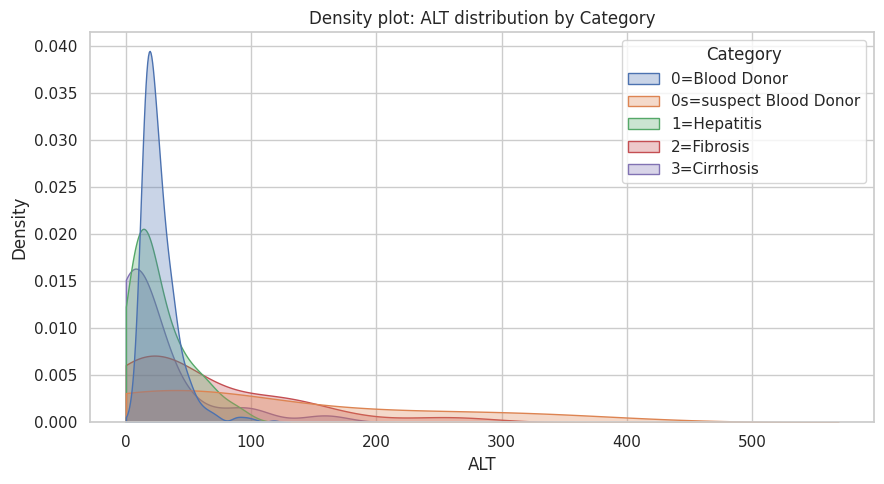

In [75]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(data=d, x="ALT", hue="Category", hue_order=CAT_ORDER, fill=True, alpha=.3,
            common_norm=False, clip=(0, None), ax=ax)
ax.set(title="Density plot: ALT distribution by Category")
save_fig("08_density_alt_by_category", fig)

### 8.10 Side-by-side box plots (QP4 Q9, QP7 Q9)

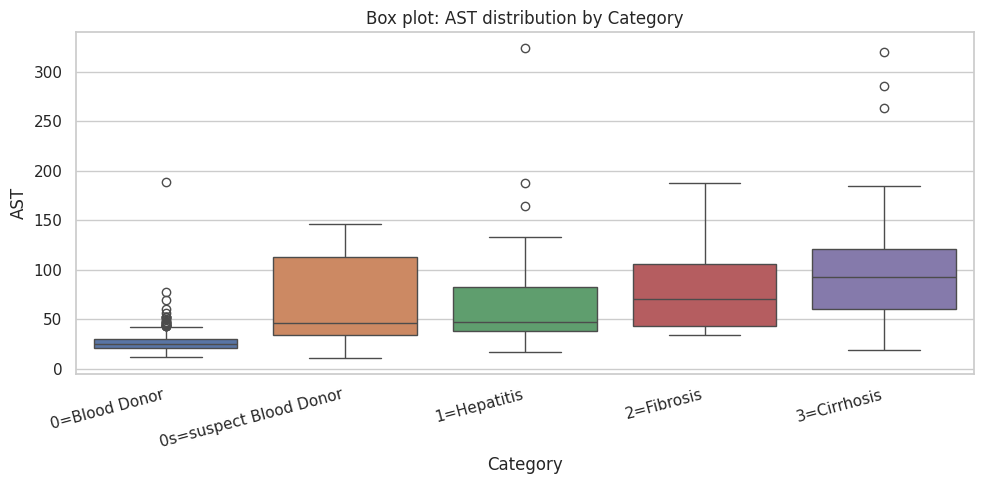

In [76]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=d, x="Category", y="AST", hue="Category", order=CAT_ORDER, legend=False, ax=ax)
ax.set(title="Box plot: AST distribution by Category")
rotate_xticks(ax, 15)
save_fig("08_boxplot_ast_by_category", fig)

### 8.11 Violin plot (QP4 Q10, QP7 Q9)

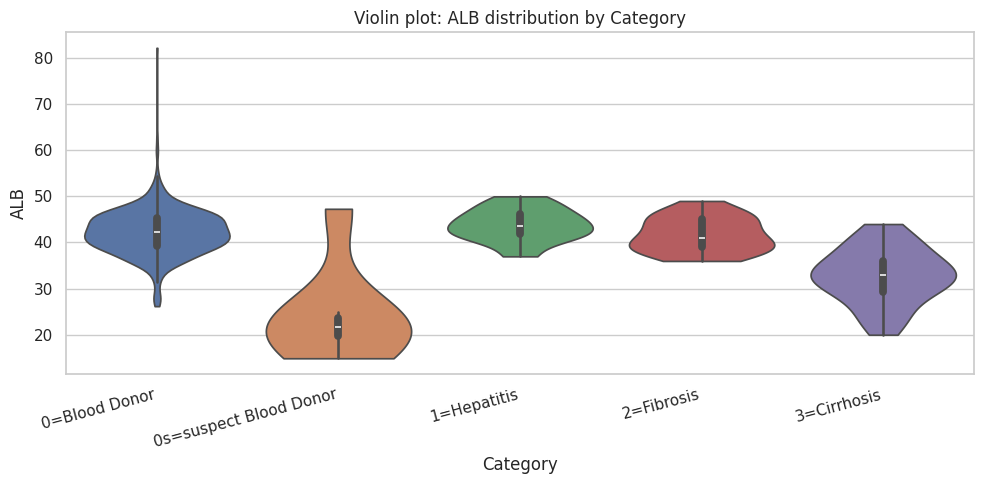

In [77]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=d, x="Category", y="ALB", hue="Category", order=CAT_ORDER, cut=0, legend=False, ax=ax)
ax.set(title="Violin plot: ALB distribution by Category")
rotate_xticks(ax, 15)
save_fig("08_violin_alb_by_category", fig)

### 8.12 Violin + box plot combined in a single graphic (QP4 Q11)

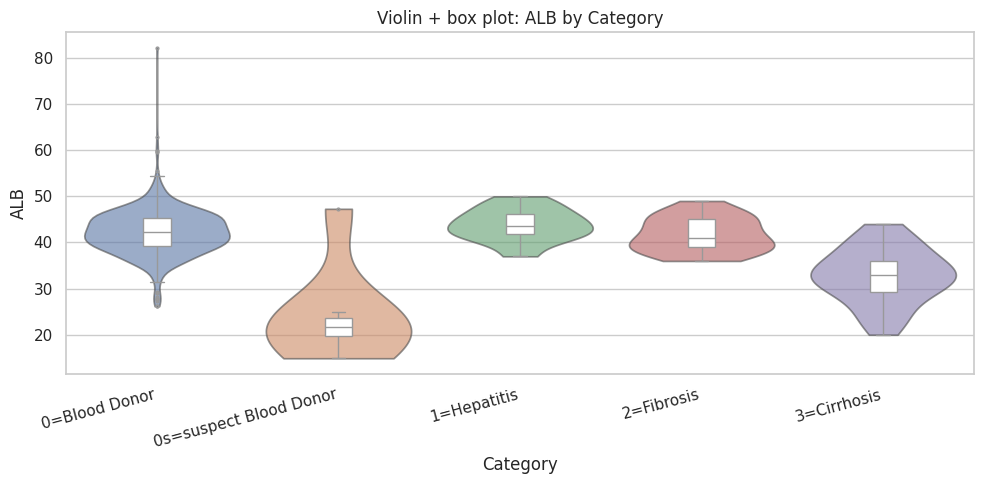

In [78]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=d, x="Category", y="ALB", hue="Category", order=CAT_ORDER, cut=0,
               inner=None, alpha=.6, legend=False, ax=ax)
sns.boxplot(data=d, x="Category", y="ALB", order=CAT_ORDER, width=.15, color="white",
            fliersize=2, ax=ax)
ax.set(title="Violin + box plot: ALB by Category")
rotate_xticks(ax, 15)
save_fig("08_violin_box_alb_by_category", fig)

## PART 9 - MULTIVARIATE ANALYSIS

In [79]:
d = df.reset_index()

### 9.1 Identify numerical and categorical variables (QP5 Q1)

In [80]:
cat_vars = d.select_dtypes(include=["category", "object"]).columns.tolist()
num_vars = d.select_dtypes("number").columns.drop("Patient_ID").tolist()
print("Categorical variables:", cat_vars)
print("Numerical variables  :", num_vars)

Categorical variables: ['Category', 'Sex']
Numerical variables  : ['Age', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT', 'AST_ALT_ratio', 'ALB_plus_ALP']


### 9.2 Scatter plot, 3 variables: ALB (x), ALP (y), Category (colour) (QP5 Q2)

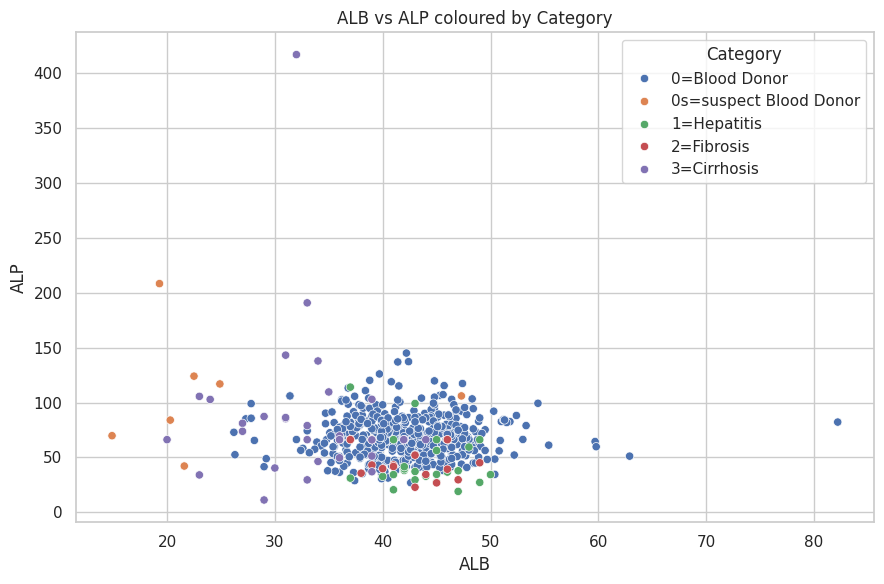

In [81]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=d, x="ALB", y="ALP", hue="Category", hue_order=CAT_ORDER, ax=ax)
ax.set_title("ALB vs ALP coloured by Category")
save_fig("09_scatter_3var_colour", fig)

### 9.3 Scatter plot, 4 variables: + shape = Sex (QP5 Q3)

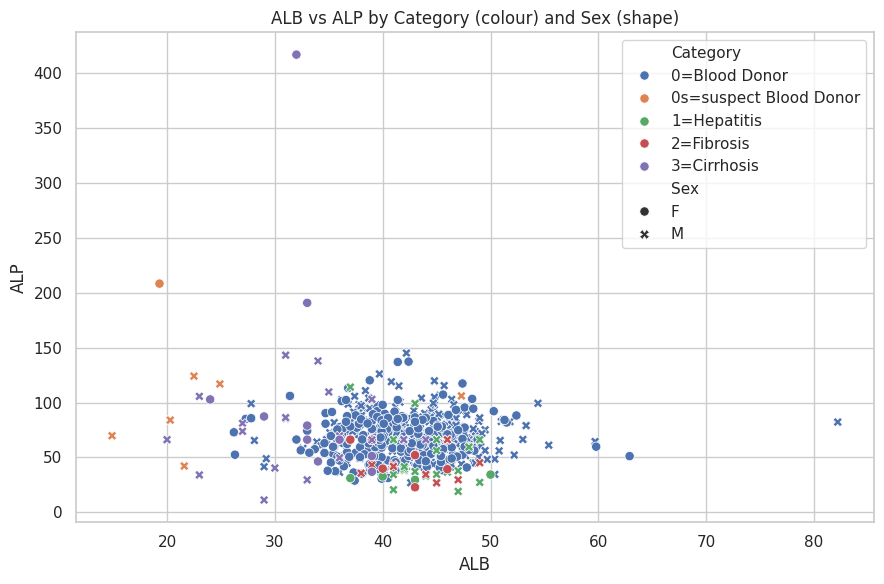

In [82]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=d, x="ALB", y="ALP", hue="Category", hue_order=CAT_ORDER, style="Sex", s=45, ax=ax)
ax.set_title("ALB vs ALP by Category (colour) and Sex (shape)")
save_fig("09_scatter_4var_shape", fig)

### 9.4 Scatter plot, 4 variables: + size = Age (QP5 Q4)

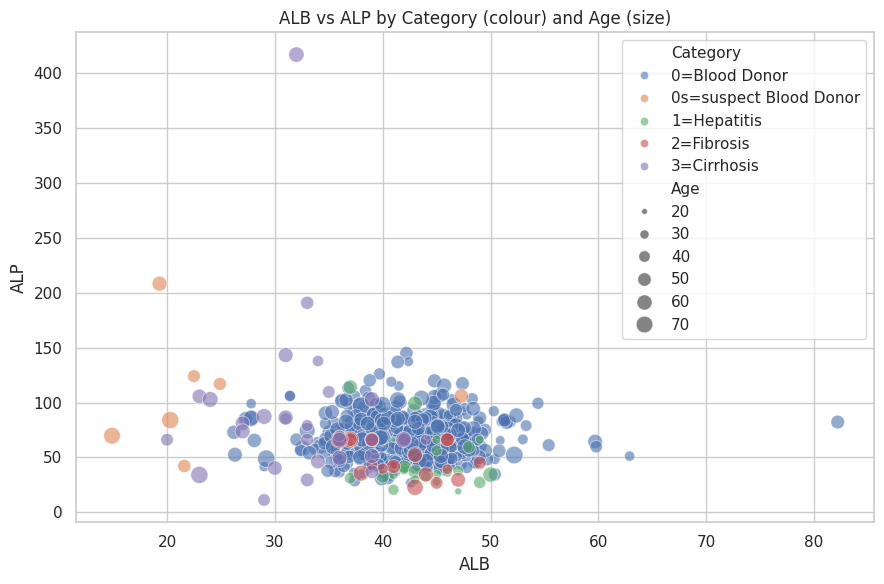

In [83]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=d, x="ALB", y="ALP", hue="Category", hue_order=CAT_ORDER, size="Age",
                sizes=(15, 160), alpha=.6, ax=ax)
ax.set_title("ALB vs ALP by Category (colour) and Age (size)")
save_fig("09_scatter_4var_size", fig)

### 9.5 Bubble plot: ALB (x), ALP (y), bubble size = AST (QP5 Q5)

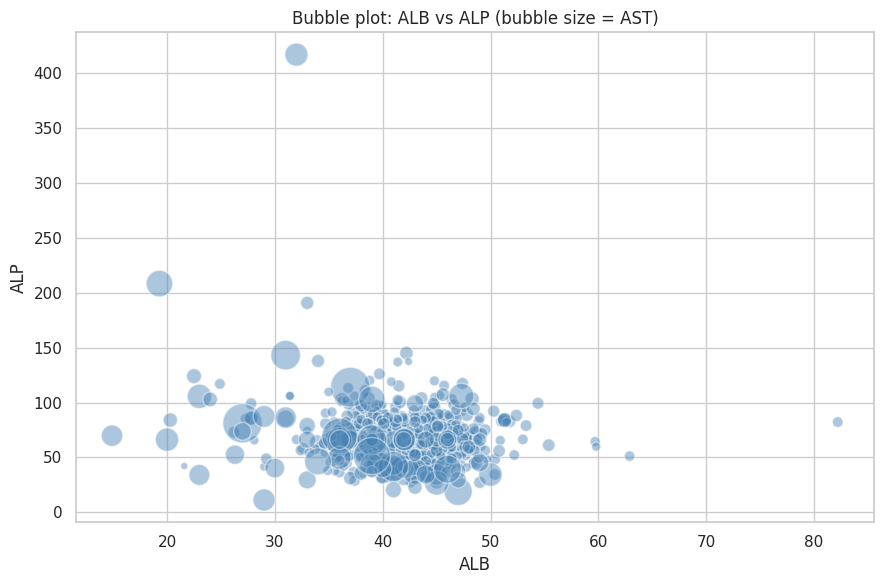

In [84]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(d["ALB"], d["ALP"], s=d["AST"] * 2.5, alpha=.45, color="steelblue", edgecolor="white")
ax.set(title="Bubble plot: ALB vs ALP (bubble size = AST)", xlabel="ALB", ylabel="ALP")
save_fig("09_bubble_plot", fig)

### 9.6 Subplots with facet_wrap equivalent (QP5 Q6)

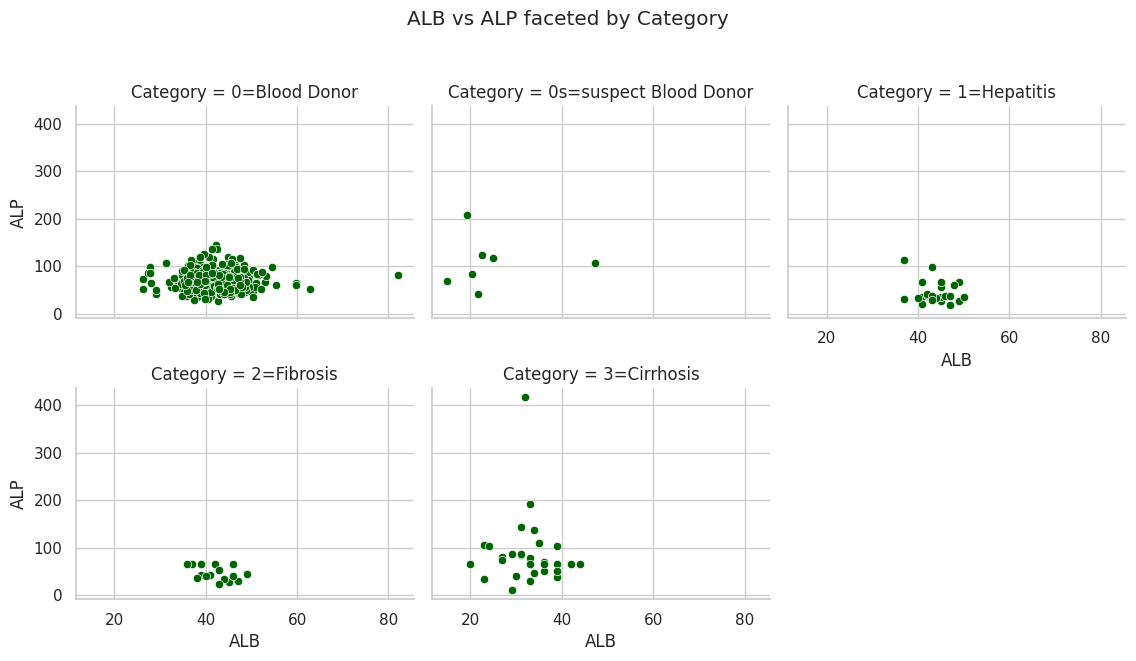

In [85]:
g = sns.relplot(data=d, x="ALB", y="ALP", col="Category", col_order=CAT_ORDER, col_wrap=3,
                height=3.2, aspect=1.2, color="darkgreen", kind="scatter")
g.figure.suptitle("ALB vs ALP faceted by Category", y=1.03)
save_fig("09_facet_wrap_category", g.figure)

### 9.7 Subplots with facet_grid equivalent: Sex (rows) x Category (columns) (QP5 Q7)

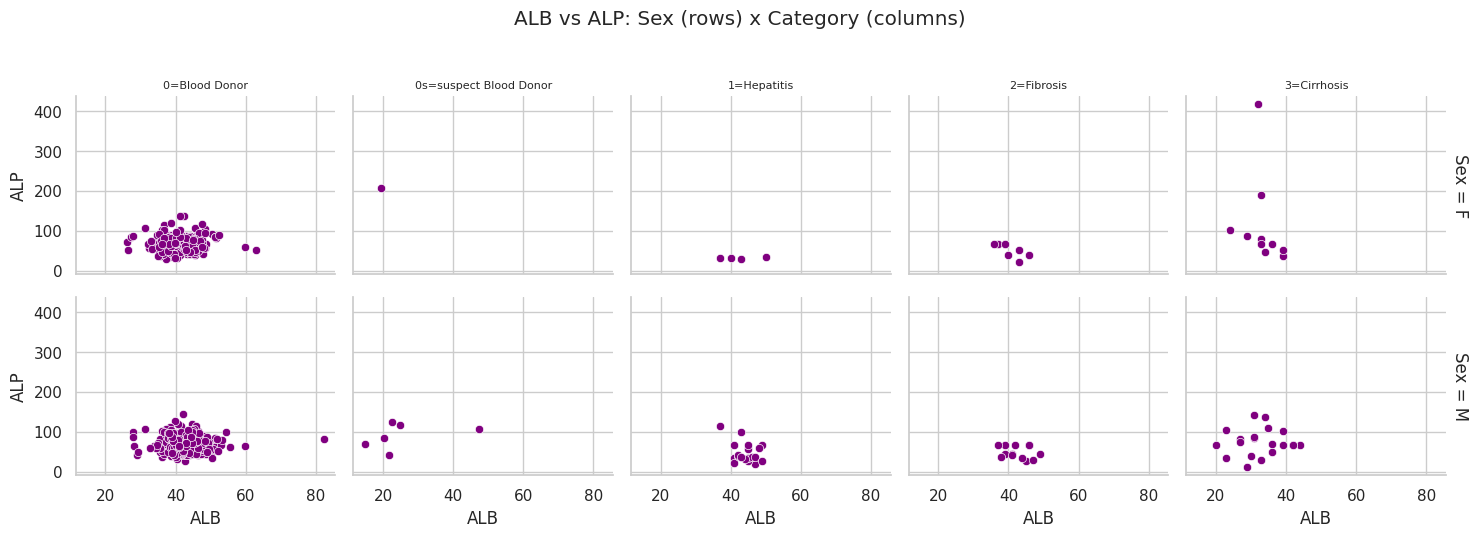

Observation: ALB is lower and ALP more spread in cirrhosis/fibrosis; the pattern is similar for both sexes, but female counts are small in the disease groups.


In [86]:
g = sns.relplot(data=d, x="ALB", y="ALP", row="Sex", col="Category", col_order=CAT_ORDER,
                height=2.6, aspect=1.15, color="purple", kind="scatter",
                facet_kws={"margin_titles": True})
g.set_titles(col_template="{col_name}", row_template="Sex = {row_name}")
for ax in g.axes[0]:
    ax.title.set_fontsize(8)
g.figure.suptitle("ALB vs ALP: Sex (rows) x Category (columns)", y=1.03)
save_fig("09_facet_grid_sex_category", g.figure)
print("Observation: ALB is lower and ALP more spread in cirrhosis/fibrosis; the pattern is similar "
      "for both sexes, but female counts are small in the disease groups.")

### 9.8 Pairs plot (scatter-plot matrix) of 4+ numerical variables (QP5 Q8, QP7 Q14)

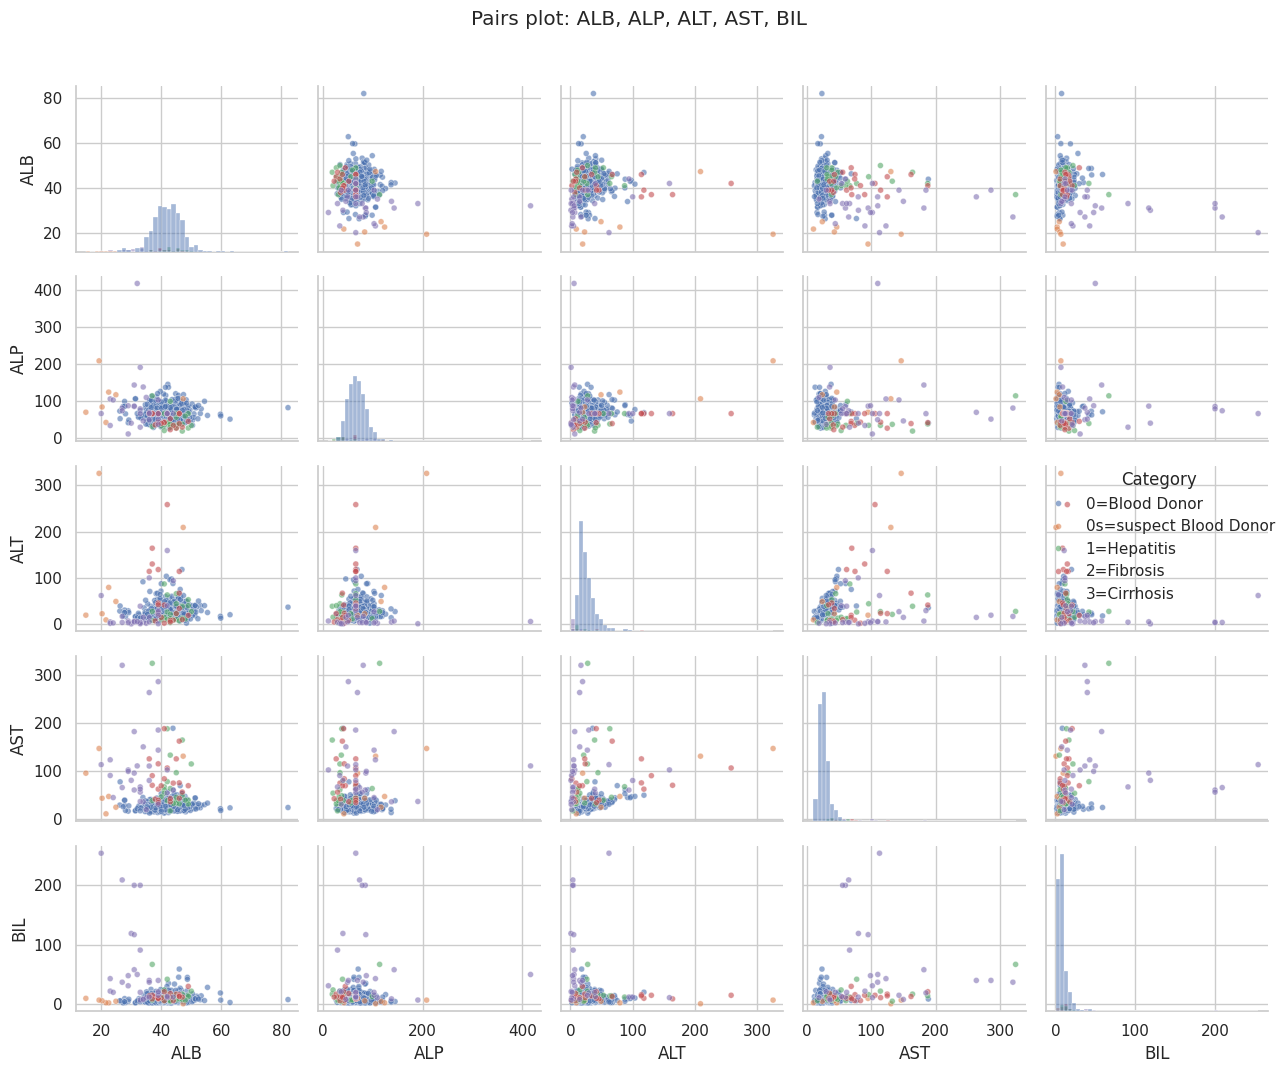

In [87]:
g = sns.pairplot(d, vars=["ALB", "ALP", "ALT", "AST", "BIL"], hue="Category", hue_order=CAT_ORDER,
                 diag_kind="hist", plot_kws={"s": 18, "alpha": .6}, height=2.1)
g.figure.suptitle("Pairs plot: ALB, ALP, ALT, AST, BIL", y=1.02)
save_fig("09_pairs_plot", g.figure)

### 9.9 Parallel-coordinate plot of 4 numerical variables, coloured by Category (QP5 Q9)

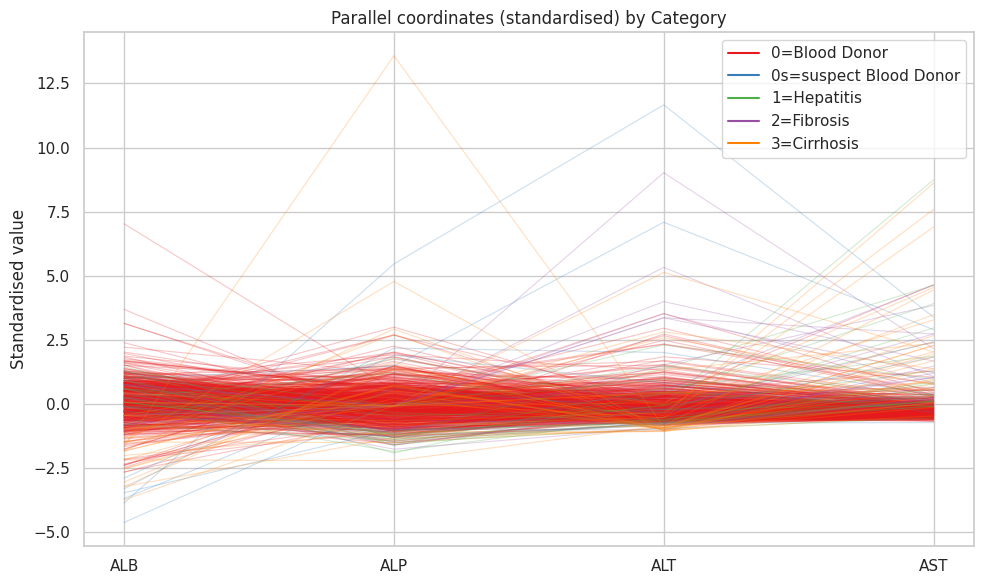

In [88]:
cols = ["ALB", "ALP", "ALT", "AST"]
z = d[cols].apply(lambda s: (s - s.mean()) / s.std())
z["Category"] = d["Category"].astype(str)
fig, ax = plt.subplots(figsize=(10, 6))
palette = dict(zip(CAT_ORDER, sns.color_palette("Set1", 5)))
for cat in CAT_ORDER:
    sub = z[z["Category"] == cat]
    for _, row in sub.iterrows():
        ax.plot(cols, row[cols].values.astype(float), color=palette[cat], alpha=.25, linewidth=.8)
    ax.plot([], [], color=palette[cat], label=cat)       # legend proxy
ax.set(title="Parallel coordinates (standardised) by Category", ylabel="Standardised value")
ax.legend()
save_fig("09_parallel_coordinates", fig)

### 9.10 Two categorical + one numerical: ALT mean & SD for each Category x Sex (QP7 Q11)

                 Category Sex  count      mean      std
0           0=Blood Donor   F    215   20.9856   9.9058
1           0=Blood Donor   M    318   30.4487  15.8246
2  0s=suspect Blood Donor   F      1  325.3000      NaN
3  0s=suspect Blood Donor   M      6   64.9167  74.9019
4             1=Hepatitis   F      4   12.1000  10.4531
5             1=Hepatitis   M     20   29.6650  22.8146
6              2=Fibrosis   F      8   57.6625  56.0492
7              2=Fibrosis   M     13   60.7923  74.6827
8             3=Cirrhosis   F     10   19.2100  30.7539
9             3=Cirrhosis   M     20   24.8500  39.4818


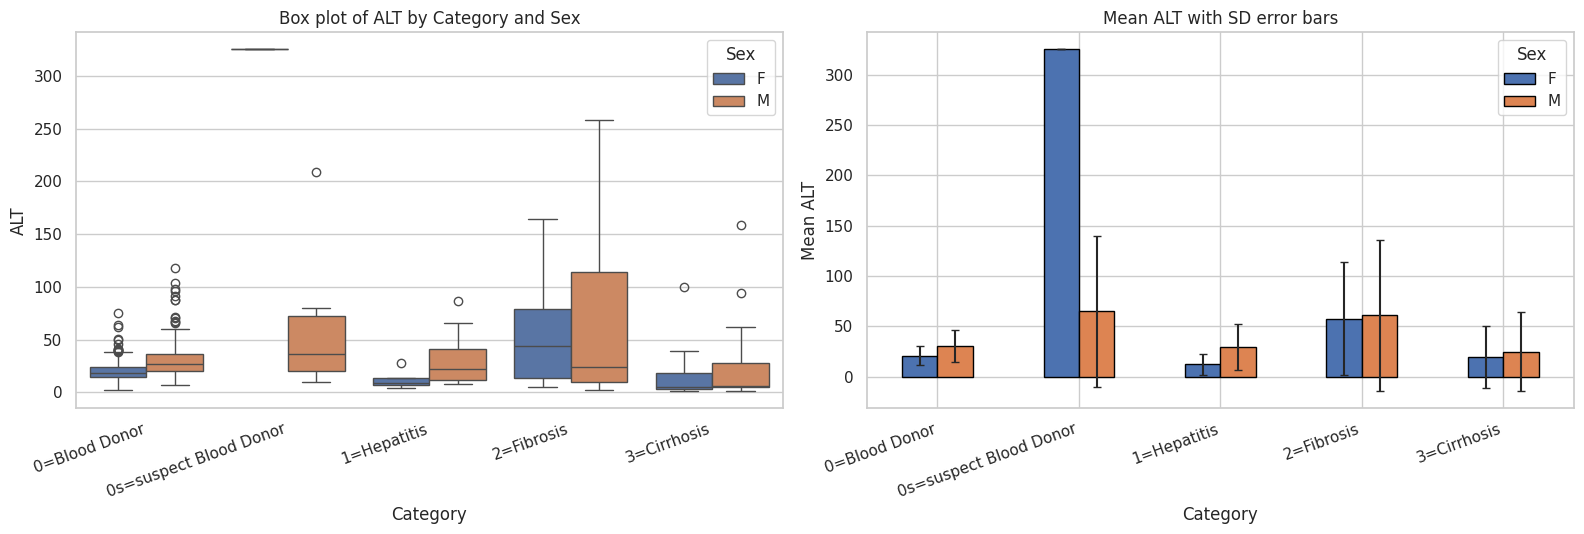

In [89]:
combo = d.groupby(["Category", "Sex"], observed=True)["ALT"].agg(["count", "mean", "std"]).round(4).reset_index()
print(combo)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.boxplot(data=d, x="Category", y="ALT", hue="Sex", order=CAT_ORDER, ax=axes[0])
axes[0].set_title("Box plot of ALT by Category and Sex"); rotate_xticks(axes[0], 20)
piv_m = combo.pivot(index="Category", columns="Sex", values="mean").reindex(CAT_ORDER)
piv_s = combo.pivot(index="Category", columns="Sex", values="std").reindex(CAT_ORDER).fillna(0)
piv_m.plot(kind="bar", yerr=piv_s, capsize=3, ax=axes[1], edgecolor="black")
axes[1].set(title="Mean ALT with SD error bars", ylabel="Mean ALT"); rotate_xticks(axes[1], 20)
save_fig("09_alt_by_category_and_sex", fig)

### 9.11 One categorical + two numerical: ALT vs AST by Sex + per-Sex correlation matrix (QP7 Q12)

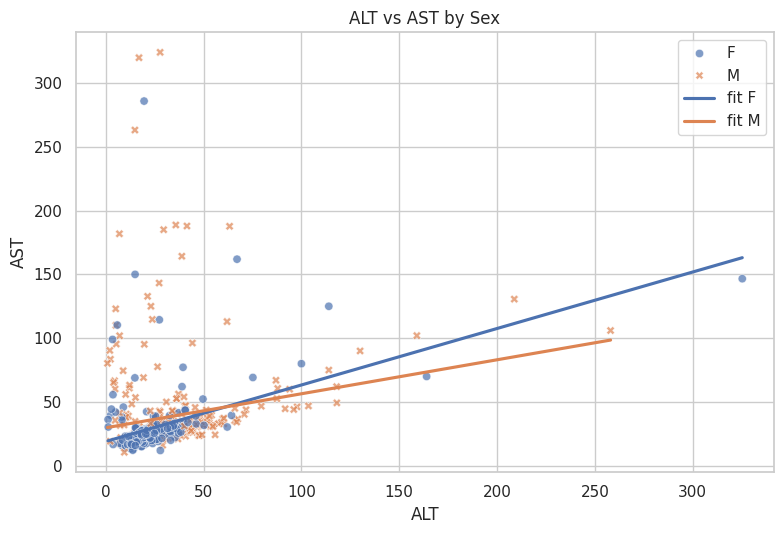


Correlation matrix for Sex = F
        ALT     AST
ALT  1.0000  0.4238
AST  0.4238  1.0000

Correlation matrix for Sex = M
        ALT     AST
ALT  1.0000  0.1833
AST  0.1833  1.0000


In [90]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=d, x="ALT", y="AST", hue="Sex", style="Sex", alpha=.7, ax=ax)
for sex, sub in d.groupby("Sex", observed=True):
    sns.regplot(data=sub, x="ALT", y="AST", scatter=False, ci=None, ax=ax, label=f"fit {sex}")
ax.set_title("ALT vs AST by Sex"); ax.legend()
save_fig("09_scatter_alt_ast_by_sex", fig)
for sex, sub in d.groupby("Sex", observed=True):
    print(f"\nCorrelation matrix for Sex = {sex}")
    print(sub[["ALT", "AST"]].corr().round(4))

## PART 10 - CORRELATION ANALYSIS

In [91]:
num = df[["Age"] + NUM_COLS_LAB]

### 10.1 Correlation matrix (Pearson) of all numeric variables (QP4 Q12, QP7 Q13)

In [92]:
corr = num.corr()
print(corr.round(3))
corr.to_csv(OUT_DIR / "10_correlation_matrix.csv")

        Age    ALB    ALP    ALT    AST    BIL    CHE   CHOL   CREA    GGT   PROT
Age   1.000 -0.197  0.168 -0.006  0.089  0.032 -0.075  0.124 -0.022  0.153 -0.154
ALB  -0.197  1.000 -0.138  0.001 -0.193 -0.222  0.376  0.205 -0.002 -0.155  0.550
ALP   0.168 -0.138  1.000  0.166  0.060  0.047  0.034  0.123  0.150  0.440 -0.056
ALT  -0.006  0.001  0.166  1.000  0.273 -0.038  0.147  0.068 -0.043  0.248  0.095
AST   0.089 -0.193  0.060  0.273  1.000  0.312 -0.209 -0.208 -0.021  0.491  0.040
BIL   0.032 -0.222  0.047 -0.038  0.312  1.000 -0.333 -0.157  0.031  0.217 -0.041
CHE  -0.075  0.376  0.034  0.147 -0.209 -0.333  1.000  0.420 -0.011 -0.110  0.293
CHOL  0.124  0.205  0.123  0.068 -0.208 -0.157  0.420  1.000 -0.047 -0.007  0.206
CREA -0.022 -0.002  0.150 -0.043 -0.021  0.031 -0.011 -0.047  1.000  0.121 -0.032
GGT   0.153 -0.155  0.440  0.248  0.491  0.217 -0.110 -0.007  0.121  1.000 -0.012
PROT -0.154  0.550 -0.056  0.095  0.040 -0.041  0.293  0.206 -0.032 -0.012  1.000


### 10.2 Heatmap of the correlation matrix (QP4 Q6, QP7 Q13)

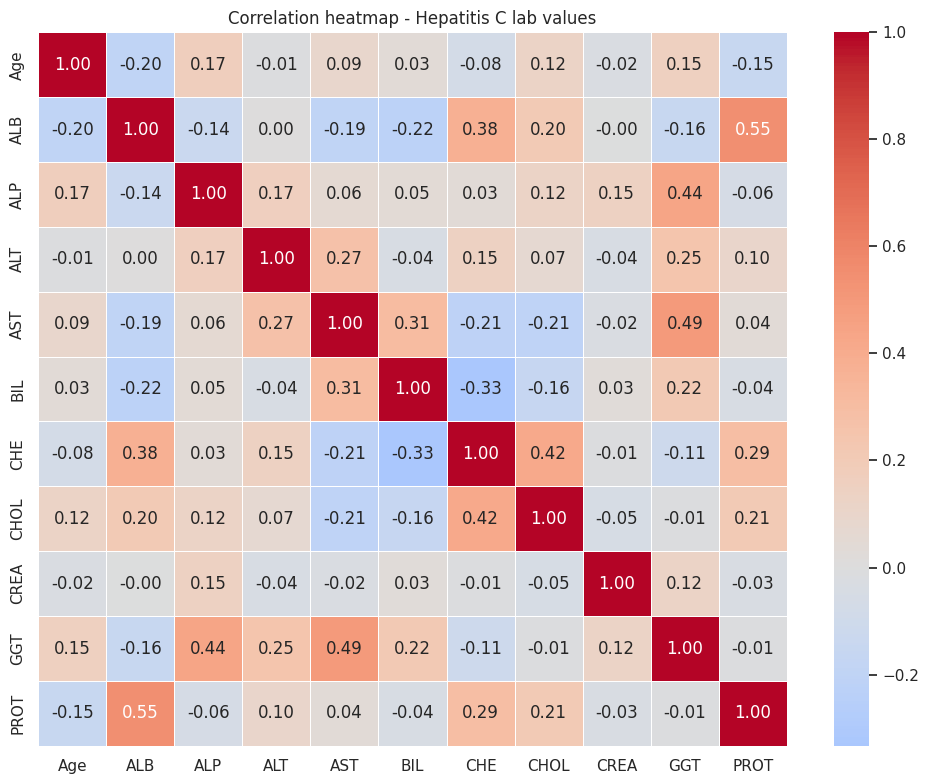

In [93]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5, ax=ax)
ax.set_title("Correlation heatmap - Hepatitis C lab values")
save_fig("10_correlation_heatmap", fig)

### 10.3 Correlogram (lower triangle, strength shown by colour) (QP4 Q12)

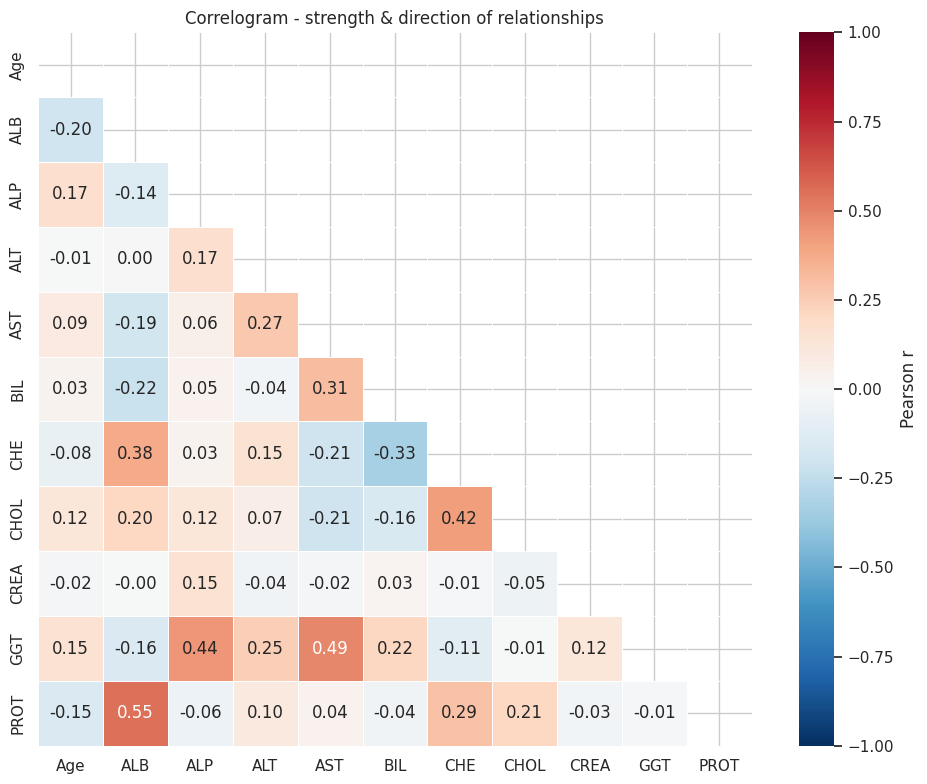

In [94]:
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlogram - strength & direction of relationships")
save_fig("10_correlogram", fig)

### 10.4 Strongest pairs

In [95]:
pairs = (corr.where(~mask).stack().rename("r").reset_index()
            .rename(columns={"level_0": "Var1", "level_1": "Var2"}))
pairs["|r|"] = pairs["r"].abs()
print(pairs.sort_values("|r|", ascending=False).head(8).round(3).to_string(index=False))

Var1 Var2      r   |r|
PROT  ALB  0.550 0.550
 GGT  AST  0.491 0.491
 GGT  ALP  0.440 0.440
CHOL  CHE  0.420 0.420
 CHE  ALB  0.376 0.376
 CHE  BIL -0.333 0.333
 BIL  AST  0.312 0.312
PROT  CHE  0.293 0.293


### 10.5 Spearman rank correlation (robust to outliers) for comparison

In [96]:
print(num.corr(method="spearman").round(3))

        Age    ALB    ALP    ALT    AST    BIL    CHE   CHOL   CREA    GGT   PROT
Age   1.000 -0.160  0.176 -0.045  0.087 -0.005 -0.053  0.171 -0.048  0.100 -0.101
ALB  -0.160  1.000 -0.053  0.182  0.027  0.102  0.327  0.139  0.243  0.032  0.512
ALP   0.176 -0.053  1.000  0.204  0.053 -0.078  0.126  0.147  0.051  0.150  0.021
ALT  -0.045  0.182  0.204  1.000  0.496  0.141  0.328  0.166  0.297  0.419  0.218
AST   0.087  0.027  0.053  0.496  1.000  0.356  0.102 -0.061  0.163  0.505  0.171
BIL  -0.005  0.102 -0.078  0.141  0.356  1.000 -0.068 -0.115  0.190  0.247  0.144
CHE  -0.053  0.327  0.126  0.328  0.102 -0.068  1.000  0.396  0.210  0.156  0.293
CHOL  0.171  0.139  0.147  0.166 -0.061 -0.115  0.396  1.000  0.069  0.063  0.155
CREA -0.048  0.243  0.051  0.297  0.163  0.190  0.210  0.069  1.000  0.148  0.132
GGT   0.100  0.032  0.150  0.419  0.505  0.247  0.156  0.063  0.148  1.000  0.184
PROT -0.101  0.512  0.021  0.218  0.171  0.144  0.293  0.155  0.132  0.184  1.000


## PART 11 - SIMPLE LINEAR REGRESSION  (QP10)

In [97]:
x_name, y_name = "ALT", "AST"

### 11.1 Choose X (independent) and Y (dependent) (QP10 Q5)

In [98]:
print(f"X = {x_name} (alanine transaminase), Y = {y_name} (aspartate transaminase)")
data = df[[x_name, y_name]].rename(columns={x_name: "X_ALT", y_name: "Y_AST"})
print(data.head(10))

X = ALT (alanine transaminase), Y = AST (aspartate transaminase)
            X_ALT  Y_AST
Patient_ID              
1             7.7   22.1
2            18.0   24.7
3            36.2   52.6
4            30.6   22.6
5            32.6   24.8
6            18.5   19.7
7            17.5   17.8
8            35.8   31.1
9            23.2   21.2
10           20.3   20.0


### 11.2 Mean, median, variance, SD (QP10 Q6)

In [99]:
print(pd.DataFrame({"Mean": data.mean(), "Median": data.median(),
                    "Variance": data.var(), "Std.Dev": data.std()}).round(4))

          Mean  Median   Variance  Std.Dev
X_ALT  28.4420    23.0   647.6968  25.4499
Y_AST  34.7863    25.9  1094.9938  33.0907


### 11.3 Histograms (matplotlib hist + seaborn histplot) (QP10 Q7-Q8)

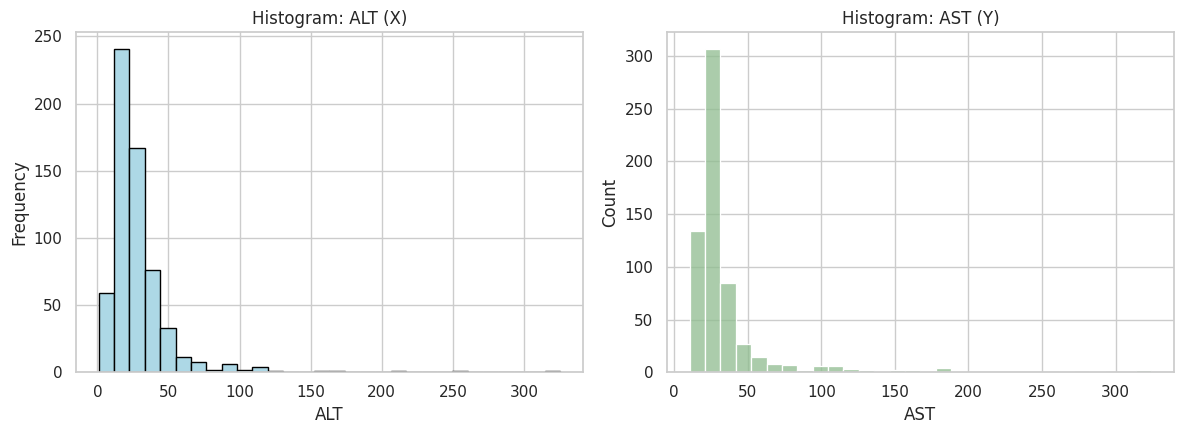

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(data["X_ALT"], bins=30, color="lightblue", edgecolor="black")
axes[0].set(title="Histogram: ALT (X)", xlabel="ALT", ylabel="Frequency")
sns.histplot(data["Y_AST"], bins=30, color="darkseagreen", edgecolor="white", ax=axes[1])
axes[1].set(title="Histogram: AST (Y)", xlabel="AST")
save_fig("11_histograms_alt_ast", fig)

### 11.4 Density curves of the standardised variables (QP10 Q9)

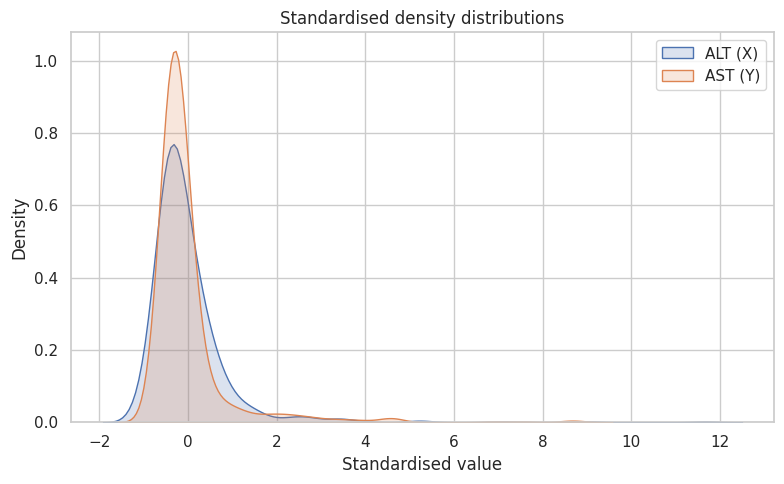

In [101]:
z = (data - data.mean()) / data.std()
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(z["X_ALT"], fill=True, alpha=.2, label="ALT (X)", ax=ax)
sns.kdeplot(z["Y_AST"], fill=True, alpha=.2, label="AST (Y)", ax=ax)
ax.set(title="Standardised density distributions", xlabel="Standardised value"); ax.legend()
save_fig("11_density_alt_ast", fig)

### 11.5 Box plots of X and Y (QP10 Q10)

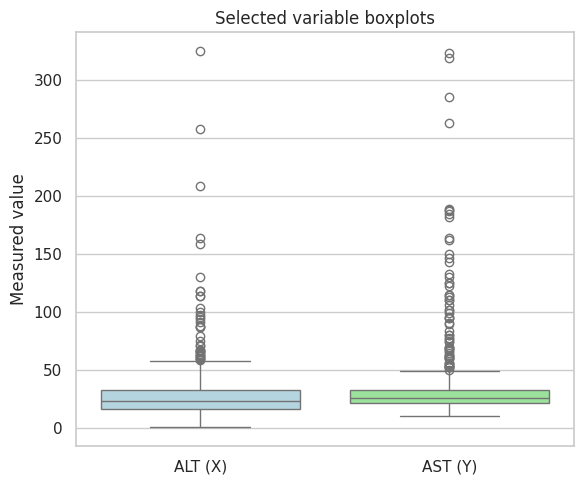

In [102]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=data.rename(columns={"X_ALT": "ALT (X)", "Y_AST": "AST (Y)"}),
            palette=["lightblue", "lightgreen"], ax=ax)
ax.set(title="Selected variable boxplots", ylabel="Measured value")
save_fig("11_boxplots_alt_ast", fig)

### 11.6 Scatter plot (QP10 Q11), Pearson correlation (Q12), linear trend (Q13)

Pearson correlation r = 0.2733


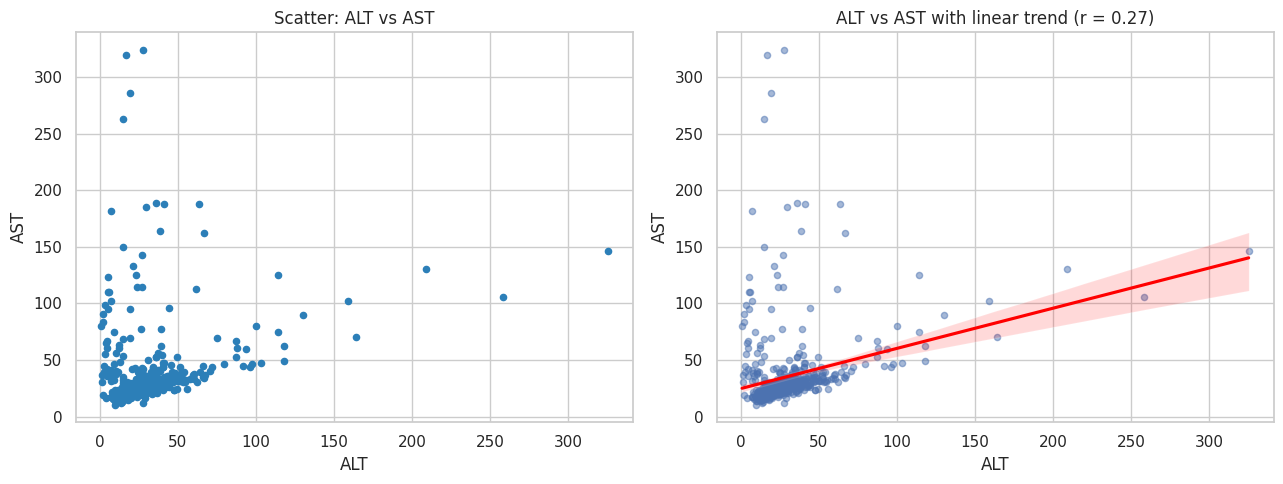

In [103]:
r = data["X_ALT"].corr(data["Y_AST"])
print(f"Pearson correlation r = {r:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(data["X_ALT"], data["Y_AST"], color="#2C7FB8", s=20)
axes[0].set(title="Scatter: ALT vs AST", xlabel="ALT", ylabel="AST")
sns.regplot(data=data, x="X_ALT", y="Y_AST", scatter_kws={"alpha": .5, "s": 20},
            line_kws={"color": "red"}, ax=axes[1])
axes[1].set(title=f"ALT vs AST with linear trend (r = {r:.2f})", xlabel="ALT", ylabel="AST")
save_fig("11_scatter_and_trend", fig)

### 11.7 80% / 20% train-test split with a fixed seed (QP10 Q14)

In [104]:
train, test = train_test_split(data, test_size=0.2, random_state=SEED)
print(f"Train rows: {len(train)} | Test rows: {len(test)}")

Train rows: 492 | Test rows: 123


### 11.8 Fit the model with OLS and print the summary (QP10 Q15-Q16)

In [105]:
model = smf.ols("Y_AST ~ X_ALT", data=train).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Y_AST   R-squared:                       0.069
Model:                            OLS   Adj. R-squared:                  0.067
Method:                 Least Squares   F-statistic:                     36.39
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           3.19e-09
Time:                        10:56:54   Log-Likelihood:                -2432.9
No. Observations:                 492   AIC:                             4870.
Df Residuals:                     490   BIC:                             4878.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     25.1646      2.264     11.116      0.0

### 11.9 Coefficients, equation, significance, R-squared (QP10 Q17-Q20)

In [106]:
b0, b1 = model.params["Intercept"], model.params["X_ALT"]
print(f"Intercept = {b0:.4f}\nSlope     = {b1:.4f}")
print(f"Regression equation:  AST = {b0:.4f} + {b1:.4f} x ALT")
print("\nCoefficient p-values:"); print(model.pvalues.apply(lambda p: f"{p:.3e}"))
sig = "statistically significant" if model.pvalues["X_ALT"] < .05 else "not significant"
print(f"=> ALT is {sig} at the 5% level.")
print(f"R-squared = {model.rsquared:.4f} | Adjusted R-squared = {model.rsquared_adj:.4f}")
print(f"Interpretation: each +1 U/L in ALT is associated with a {b1:.2f} U/L rise in AST; "
      f"ALT explains {model.rsquared * 100:.1f}% of AST variance.")

Intercept = 25.1646
Slope     = 0.3507
Regression equation:  AST = 25.1646 + 0.3507 x ALT

Coefficient p-values:
Intercept    9.418e-26
X_ALT        3.192e-09
dtype: object
=> ALT is statistically significant at the 5% level.
R-squared = 0.0691 | Adjusted R-squared = 0.0672
Interpretation: each +1 U/L in ALT is associated with a 0.35 U/L rise in AST; ALT explains 6.9% of AST variance.


### 11.10 Prediction errors on the TEST set: residuals, MAE, MSE, RMSE, MAPE (QP10 Q21-Q25)

In [107]:
pred = model.predict(test)
resid = test["Y_AST"] - pred
mae = resid.abs().mean()
mse = (resid ** 2).mean()
rmse = np.sqrt(mse)
nz = test["Y_AST"] != 0
mape = (resid[nz].abs() / test["Y_AST"][nz].abs()).mean() * 100
print(pd.DataFrame({"Actual": test["Y_AST"], "Predicted": pred, "Residual": resid}).head(10).round(3))
print(f"\nMAE  = {mae:.4f}\nMSE  = {mse:.4f}\nRMSE = {rmse:.4f}\nMAPE = {mape:.2f}% (zero actuals excluded)")

            Actual  Predicted  Residual
Patient_ID                             
83            29.1     33.861    -4.761
12            20.0     28.776    -8.776
446           26.0     35.123    -9.123
522           17.3     29.653   -12.353
335           16.3     29.583   -13.283
273           28.1     33.475    -5.375
139           31.6     39.682    -8.082
405           19.1     32.143   -13.043
362           30.9     39.226    -8.326
416           21.8     32.178   -10.378

MAE  = 12.7868
MSE  = 438.7445
RMSE = 20.9462
MAPE = 37.82% (zero actuals excluded)


### 11.11 Diagnostics: fitted line on test data and residual plot

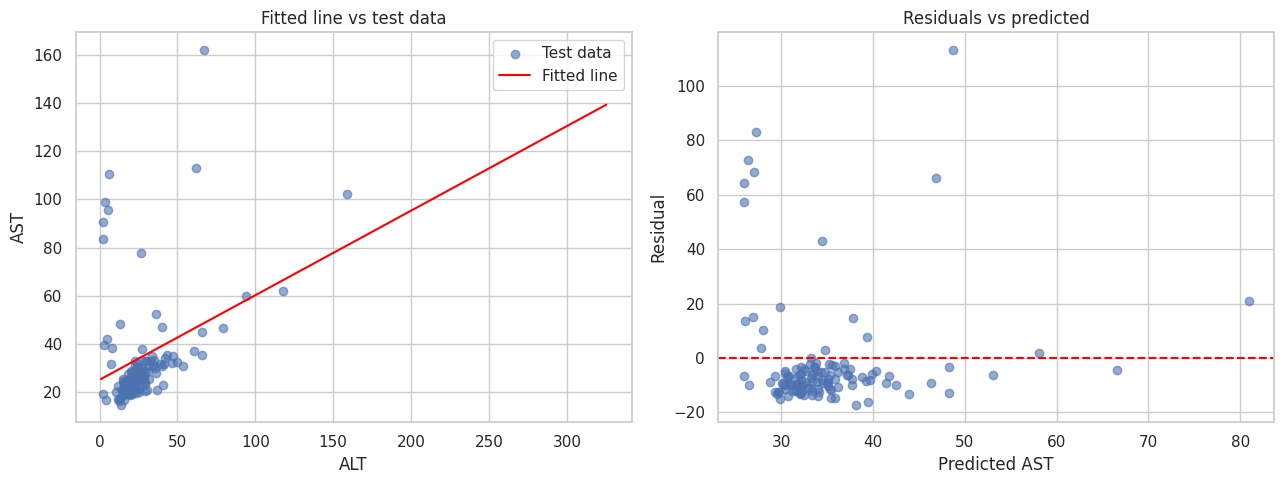

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(test["X_ALT"], test["Y_AST"], alpha=.6, label="Test data")
xs = np.linspace(data["X_ALT"].min(), data["X_ALT"].max(), 100)
axes[0].plot(xs, b0 + b1 * xs, color="red", label="Fitted line")
axes[0].set(title="Fitted line vs test data", xlabel="ALT", ylabel="AST"); axes[0].legend()
axes[1].scatter(pred, resid, alpha=.6); axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(title="Residuals vs predicted", xlabel="Predicted AST", ylabel="Residual")
save_fig("11_regression_diagnostics", fig)

## PART 12 - PRINCIPAL COMPONENT ANALYSIS  (QP9)

In [109]:
reg_no = REG_NO

### 12.1 Number of rows and columns (QP9 Q2)

In [110]:
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

Rows: 615 | Columns: 15


### 12.2 Extract numeric columns, clean and normalise -> data_scaled (QP9 Q3)

In [111]:
numeric = df[["Age"] + NUM_COLS_LAB].dropna()
scaler = StandardScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(numeric), columns=numeric.columns, index=numeric.index)
print(data_scaled.describe().loc[["mean", "std"]].round(3))

        Age    ALB    ALP    ALT    AST    BIL    CHE   CHOL   CREA    GGT   PROT
mean  0.000  0.000 -0.000  0.000  0.000  0.000 -0.000  0.000  0.000 -0.000 -0.000
std   1.001  1.001  1.001  1.001  1.001  1.001  1.001  1.001  1.001  1.001  1.001


### 12.3 Fit PCA and print the summary (QP9 Q4)

In [112]:
pca = PCA().fit(data_scaled)
pcs = [f"PC{i + 1}" for i in range(pca.n_components_)]
summary = pd.DataFrame({
    "Std.Dev": np.sqrt(pca.explained_variance_),
    "Eigenvalue": pca.explained_variance_,
    "Proportion of variance": pca.explained_variance_ratio_,
    "Cumulative proportion": np.cumsum(pca.explained_variance_ratio_),
}, index=pcs).round(4)
print(summary)
n80 = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= .80)) + 1
print(f"\n{n80} components are needed to explain >= 80% of the variance.")

      Std.Dev  Eigenvalue  Proportion of variance  Cumulative proportion
PC1    1.5703      2.4657                  0.2238                 0.2238
PC2    1.3493      1.8206                  0.1652                 0.3890
PC3    1.1697      1.3683                  0.1242                 0.5132
PC4    1.0475      1.0972                  0.0996                 0.6128
PC5    0.9822      0.9646                  0.0876                 0.7004
PC6    0.8731      0.7623                  0.0692                 0.7695
PC7    0.8379      0.7021                  0.0637                 0.8333
PC8    0.7670      0.5883                  0.0534                 0.8867
PC9    0.7029      0.4940                  0.0448                 0.9315
PC10   0.6480      0.4199                  0.0381                 0.9696
PC11   0.5785      0.3347                  0.0304                 1.0000

7 components are needed to explain >= 80% of the variance.


### 12.4 Scree plot with data labels, y-axis 0-60 (QP9 Q5)

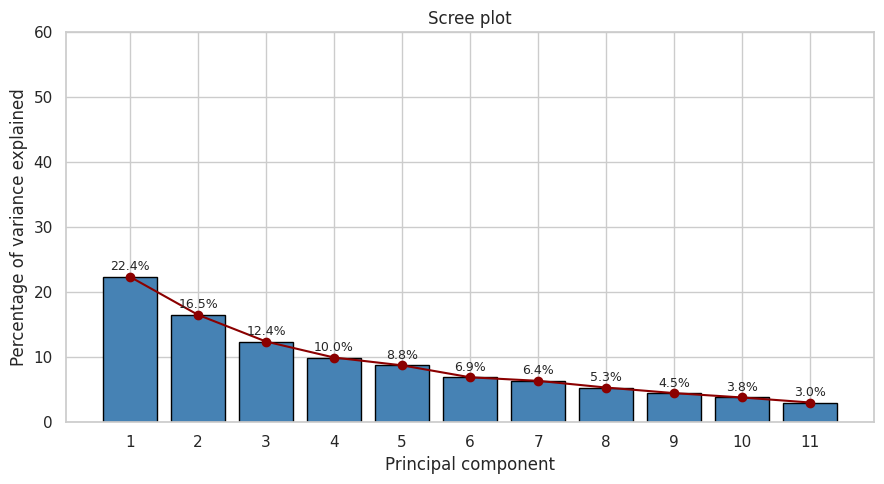

In [113]:
pct = pca.explained_variance_ratio_ * 100
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(range(1, len(pct) + 1), pct, color="steelblue", edgecolor="black")
ax.plot(range(1, len(pct) + 1), pct, mar788Iker="o", color="darkred")
for i, v in enumerate(pct, 1):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
ax.set(ylim=(0, 60), xticks=range(1, len(pct) + 1), xlabel="Principal component",
       ylabel="Percentage of variance explained", title="Scree plot")
save_fig("12_pca_scree_plot", fig)

### 12.5 PCA biplot with non-overlapping labels (QP9 Q6)

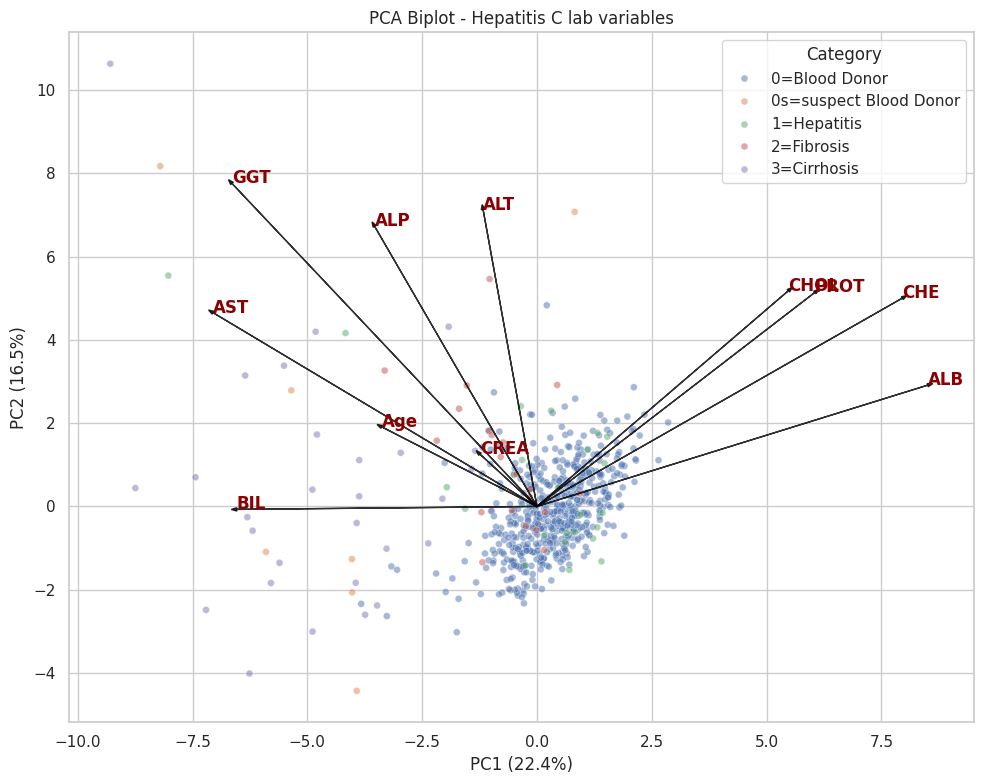

In [114]:
scores = pca.transform(data_scaled)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
cats = df.loc[data_scaled.index, "Category"].astype(str)
fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=cats, hue_order=CAT_ORDER, alpha=.5, s=25, ax=ax)
scale = np.abs(scores[:, :2]).max() / np.abs(loadings[:, :2]).max() * .8
texts = []
for i, name in enumerate(data_scaled.columns):
    ax.arrow(0, 0, loadings[i, 0] * scale, loadings[i, 1] * scale, color="black",
             head_width=.08, alpha=.8)
    texts.append(ax.text(loadings[i, 0] * scale, loadings[i, 1] * scale, name,
                         color="darkred", fontweight="bold"))
if adjust_text is not None:
    adjust_text(texts, ax=ax)                              # avoids overlapping labels
ax.set(xlabel=f"PC1 ({pct[0]:.1f}%)", ylabel=f"PC2 ({pct[1]:.1f}%)",
       title="PCA Biplot - Hepatitis C lab variables")
save_fig("12_pca_biplot", fig)

### 12.6 PCA scores data frame - first six rows (QP9 Q7)

In [115]:
pca_scores = pd.DataFrame(scores, columns=pcs, index=data_scaled.index)
print(pca_scores.head(6).round(4))
print("\nTop loadings on PC1 and PC2:")
print(pd.DataFrame(pca.components_[:2].T, index=data_scaled.columns, columns=["PC1", "PC2"]).round(3))

               PC1     PC2     PC3     PC4     PC5     PC6     PC7     PC8     PC9    PC10    PC11
Patient_ID                                                                                        
1          -0.4173 -2.1382 -0.8717  1.0988  1.1701 -0.2129 -0.4421 -0.2997  0.3362 -0.1937 -0.2849
2           1.1233 -0.2121 -0.5633  0.4212  0.8113 -0.8903 -0.1317 -0.6391  0.9260 -1.1316 -0.4614
3           1.0446  0.7888 -1.5984  0.6134  0.4933 -0.4296 -0.4097 -0.0854 -0.1491 -0.4938  0.3660
4           0.4391 -0.5936 -1.5127  0.5104  0.3868 -0.6704  0.0205  0.1943 -0.2988 -0.0265 -0.4825
5          -0.0405 -0.6207 -0.3666  0.3951  1.4469 -0.9798 -0.1160 -0.2047  0.6301 -0.0165 -0.0847
6           0.8739  0.1576 -0.6254  0.8862  0.2321 -0.6702  0.7423 -1.2813 -0.2964  0.2708 -1.0942

Top loadings on PC1 and PC2:
        PC1    PC2
Age  -0.177  0.116
ALB   0.445  0.177
ALP  -0.185  0.409
ALT  -0.061  0.434
AST  -0.369  0.283
BIL  -0.342 -0.004
CHE   0.416  0.304
CHOL  0.286  0.315
CREA -0

### 12.7 PC1 vs PC2 scatter: blue circular points, registration number in the title (QP9 Q8)

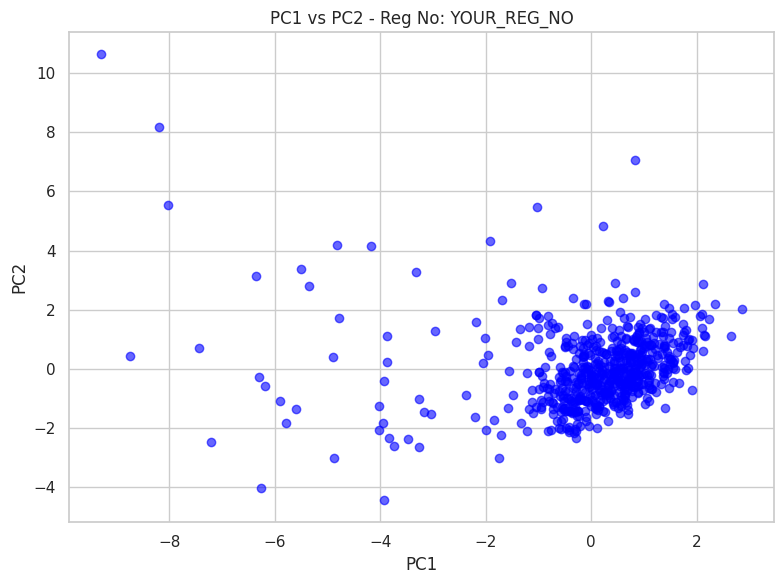

In [116]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", alpha=.6)
ax.set(xlabel="PC1", ylabel="PC2", title=f"PC1 vs PC2 - Reg No: {reg_no}")
save_fig("12_pca_pc1_vs_pc2", fig)

## PART 13 - CLUSTERING  (QP8)

### 13.1 View dataset, check missing values, dependent-variable distribution (QP8 Q2-Q4)

In [117]:
print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print(df["Category"].value_counts().reindex(CAT_ORDER))

                 Category  Age Sex   ALB   ALP   ALT   AST   BIL    CHE  CHOL   CREA   GGT  PROT  AST_ALT_ratio  ALB_plus_ALP
Patient_ID                                                                                                                   
1           0=Blood Donor   32   M  38.5  52.5   7.7  22.1   7.5   6.93  3.23  106.0  12.1  69.0       2.870130          91.0
2           0=Blood Donor   32   M  38.5  70.3  18.0  24.7   3.9  11.17  4.80   74.0  15.6  76.5       1.372222         108.8
3           0=Blood Donor   32   M  46.9  74.7  36.2  52.6   6.1   8.84  5.20   86.0  33.2  79.3       1.453039         121.6
4           0=Blood Donor   32   M  43.2  52.0  30.6  22.6  18.9   7.33  4.74   80.0  33.8  75.7       0.738562          95.2
5           0=Blood Donor   32   M  39.2  74.1  32.6  24.8   9.6   9.15  4.32   76.0  29.9  68.7       0.760736         113.3
Missing values: 0
Category
0=Blood Donor             533
0s=suspect Blood Donor      7
1=Hepatitis                24
2

### 13.2 Numerical features only + standardisation (QP8 Q5-Q6)

In [118]:
print("Features used:", list(data_scaled.columns))

Features used: ['Age', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']


### 13.3 K-Means with k = 2: results and cluster centres (QP8 Q7-Q9)

In [119]:
km2 = KMeans(n_clusters=2, n_init=25, random_state=SEED).fit(data_scaled)
print("Cluster sizes:", np.bincount(km2.labels_))
print("Within-cluster SS (inertia):", round(km2.inertia_, 2))
print("Cluster centres (standardised units):")
print(pd.DataFrame(km2.cluster_centers_, columns=data_scaled.columns).round(3))

Cluster sizes: [579  36]
Within-cluster SS (inertia): 5741.5
Cluster centres (standardised units):
     Age    ALB    ALP    ALT    AST    BIL    CHE   CHOL   CREA    GGT   PROT
0 -0.058  0.130 -0.065  0.001 -0.130 -0.124  0.115  0.077 -0.057 -0.125  0.093
1  0.930 -2.088  1.042 -0.008  2.095  2.000 -1.843 -1.232  0.921  2.018 -1.495


### 13.4 WCSS for k = 1..10 and elbow plot (QP8 Q10-Q11)

 k    WCSS
 1 6765.00
 2 5741.50
 3 5185.70
 4 4751.93
 5 4334.77
 6 4023.08
 7 3796.56
 8 3435.06
 9 3213.88
10 3048.82

Elbow recommendation (max distance to chord): k = 5
Silhouette scores: {2: np.float64(0.594), 3: np.float64(0.136), 4: np.float64(0.138), 5: np.float64(0.128), 6: np.float64(0.133), 7: np.float64(0.135), 8: np.float64(0.135), 9: np.float64(0.136), 10: np.float64(0.124)}


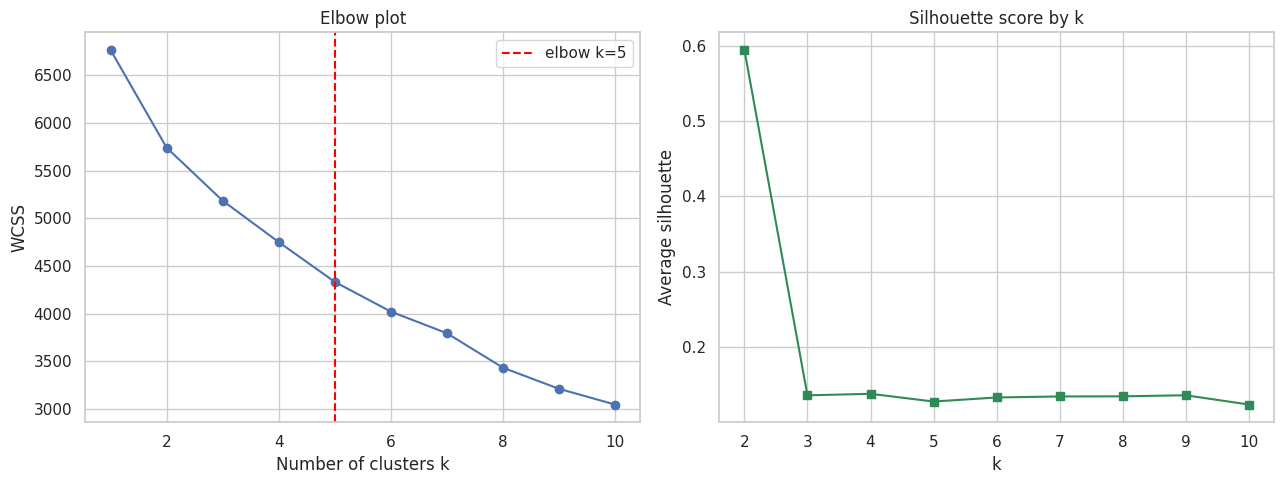

In [120]:
ks = range(1, 11)
wcss = [KMeans(n_clusters=k, n_init=25, random_state=SEED).fit(data_scaled).inertia_ for k in ks]
print(pd.DataFrame({"k": list(ks), "WCSS": np.round(wcss, 2)}).to_string(index=False))
sil = {k: silhouette_score(data_scaled, KMeans(n_clusters=k, n_init=25, random_state=SEED)
                           .fit_predict(data_scaled)) for k in range(2, 11)}

# elbow = point farthest from the straight line joining the first and last WCSS points
p1, p2 = np.array([1, wcss[0]]), np.array([10, wcss[-1]])
chord = p2 - p1
dists = [abs(chord[0] * (w - p1[1]) - chord[1] * (k - p1[0])) / np.linalg.norm(chord)
         for k, w in zip(ks, wcss)]
k_best = int(list(ks)[int(np.argmax(dists))])
print(f"\nElbow recommendation (max distance to chord): k = {k_best}")
print("Silhouette scores:", {k: round(v, 3) for k, v in sil.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(ks), wcss, marker="o")
axes[0].axvline(k_best, color="red", linestyle="--", label=f"elbow k={k_best}")
axes[0].set(title="Elbow plot", xlabel="Number of clusters k", ylabel="WCSS"); axes[0].legend()
axes[1].plot(list(sil), list(sil.values()), marker="s", color="seagreen")
axes[1].set(title="Silhouette score by k", xlabel="k", ylabel="Average silhouette")
save_fig("13_kmeans_elbow_and_silhouette", fig)

### 13.5 Final K-Means with the elbow-recommended k = k* (QP8 Q12)

Cluster sizes: {0: 213, 1: 163, 2: 216, 3: 20, 4: 3}

Clusters vs true diagnosis (cross-tab):
KMeans_cluster            0    1    2   3  4
Category                                    
0=Blood Donor           187  146  200   0  0
0s=suspect Blood Donor    0    4    1   2  0
1=Hepatitis              15    1    6   2  0
2=Fibrosis                9    4    7   1  0
3=Cirrhosis               2    8    2  15  3


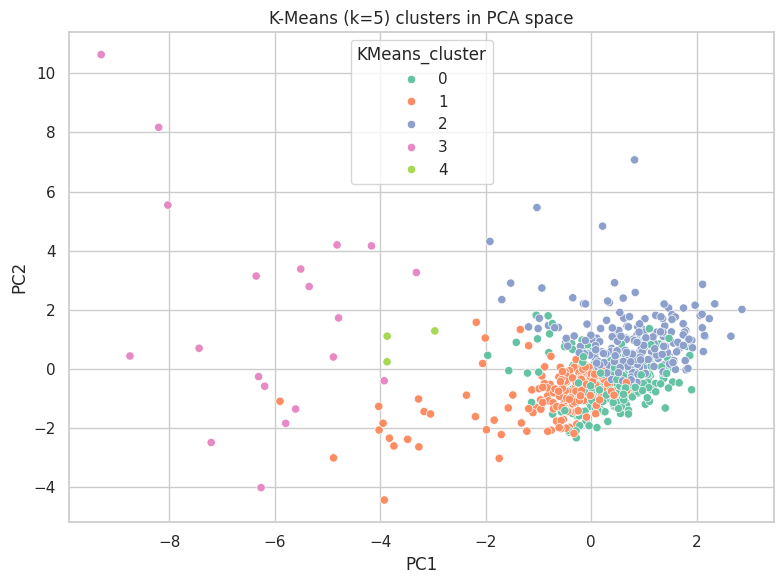

In [121]:
km = KMeans(n_clusters=k_best, n_init=25, random_state=SEED).fit(data_scaled)
labels = pd.Series(km.labels_, index=data_scaled.index, name="KMeans_cluster")
print("Cluster sizes:", labels.value_counts().sort_index().to_dict())
print("\nClusters vs true diagnosis (cross-tab):")
print(pd.crosstab(df.loc[labels.index, "Category"], labels))
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=pca_scores["PC1"], y=pca_scores["PC2"], hue=labels.astype(str), palette="Set2", ax=ax)
ax.set(title=f"K-Means (k={k_best}) clusters in PCA space")
save_fig("13_kmeans_clusters_pca", fig)

### 13.6 Hierarchical clustering: Euclidean distance + Ward linkage (QP8 Q6-Q7)

In [122]:
Z = linkage(data_scaled.values, method="ward", metric="euclidean")
print("Linkage matrix shape:", Z.shape, "(n-1 merges)")

Linkage matrix shape: (614, 4) (n-1 merges)


### 13.7 Dendrogram (QP8 Q8)

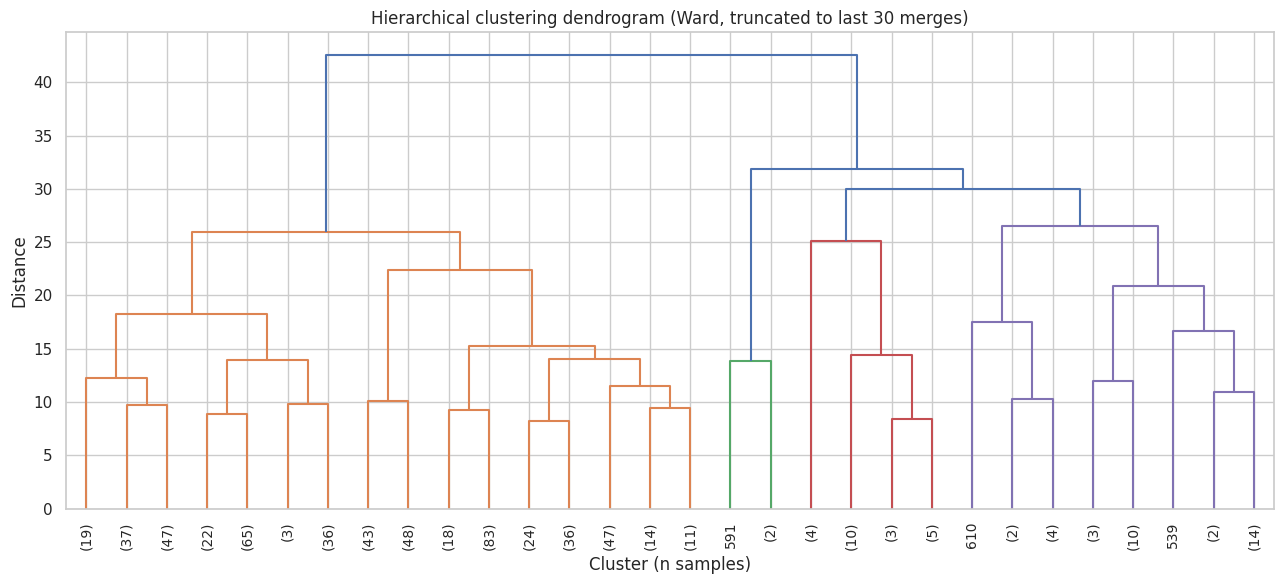

In [123]:
fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, ax=ax,
           color_threshold=Z[-3, 2])
ax.set(title="Hierarchical clustering dendrogram (Ward, truncated to last 30 merges)",
       xlabel="Cluster (n samples)", ylabel="Distance")
save_fig("13_dendrogram_ward", fig)

### 13.8 Cut into 3 clusters and display assignments + sizes (QP8 Q9-Q10)

In [124]:
hc = pd.Series(fcluster(Z, t=3, criterion="maxclust"), index=data_scaled.index, name="HC_cluster")
print("First 15 assignments:"); print(hc.head(15).to_dict())
print("\nSamples per cluster:"); print(hc.value_counts().sort_index())
print("\nClusters vs true diagnosis:")
print(pd.crosstab(df.loc[hc.index, "Category"], hc))

First 15 assignments:
{1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1, 13: 1, 14: 1, 15: 1}

Samples per cluster:
HC_cluster
1    553
2      3
3     59
Name: count, dtype: int64

Clusters vs true diagnosis:
HC_cluster                1  2   3
Category                          
0=Blood Donor           522  0  11
0s=suspect Blood Donor    0  0   7
1=Hepatitis              17  0   7
2=Fibrosis               11  0  10
3=Cirrhosis               3  3  24


## APPENDIX - TIME-SERIES ANALYSIS ON AirPassengers  (QP6)

In [125]:
print("The Hepatitis data has no time axis, so QP6 (which uses R's built-in AirPassengers "
      "dataset) is run separately on the classic monthly series 1949-1960.")

values = [112,118,132,129,121,135,148,148,136,119,104,118,
          115,126,141,135,125,149,170,170,158,133,114,140,
          145,150,178,163,172,178,199,199,184,162,146,166,
          171,180,193,181,183,218,230,242,209,191,172,194,
          196,196,236,235,229,243,264,272,237,211,180,201,
          204,188,235,227,234,264,302,293,259,229,203,229,
          242,233,267,269,270,315,364,347,312,274,237,278,
          284,277,317,313,318,374,413,405,355,306,271,306,
          315,301,356,348,355,422,465,467,404,347,305,336,
          340,318,362,348,363,435,491,505,404,359,310,337,
          360,342,406,396,420,472,548,559,463,407,362,405,
          417,391,419,461,472,535,622,606,508,461,390,432]
ts = pd.Series(values, index=pd.date_range("1949-01", periods=len(values), freq="MS"), name="Passengers")

The Hepatitis data has no time axis, so QP6 (which uses R's built-in AirPassengers dataset) is run separately on the classic monthly series 1949-1960.


### A.1 First/last five observations; start, end, frequency, class (QP6 Q2-Q4)

In [126]:
print(ts.head(5)); print(ts.tail(5))
print(f"Start: {ts.index[0]:%b %Y} | End: {ts.index[-1]:%b %Y} | Frequency: 12 (monthly) | "
      f"Type: {type(ts).__name__} with DatetimeIndex | n = {len(ts)}")

1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64
1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers, dtype: int64
Start: Jan 1949 | End: Dec 1960 | Frequency: 12 (monthly) | Type: Series with DatetimeIndex | n = 144


### A.2 Monthly trend plot (QP6 Q5)

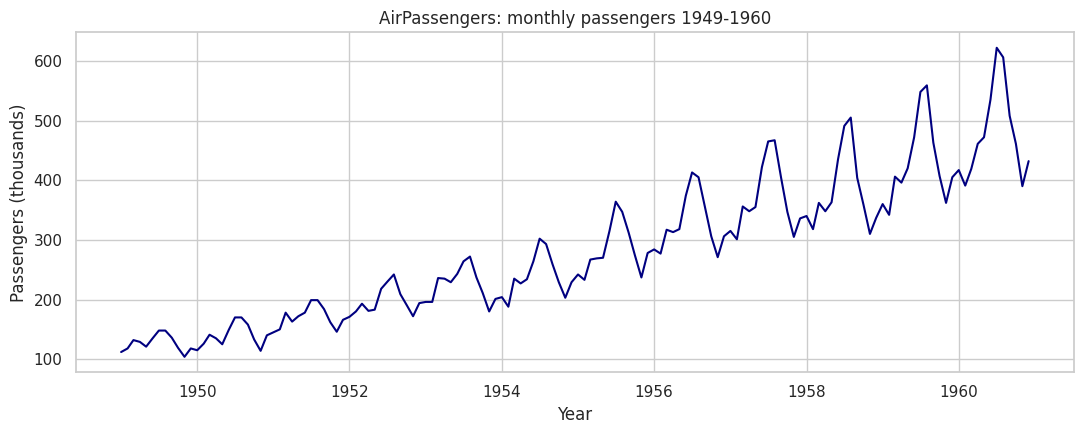

In [127]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(ts, color="navy")
ax.set(title="AirPassengers: monthly passengers 1949-1960", xlabel="Year", ylabel="Passengers (thousands)")
save_fig("A1_timeseries_trend", fig)

### A.3 Decomposition into trend, seasonal and random (QP6 Q6-Q7)

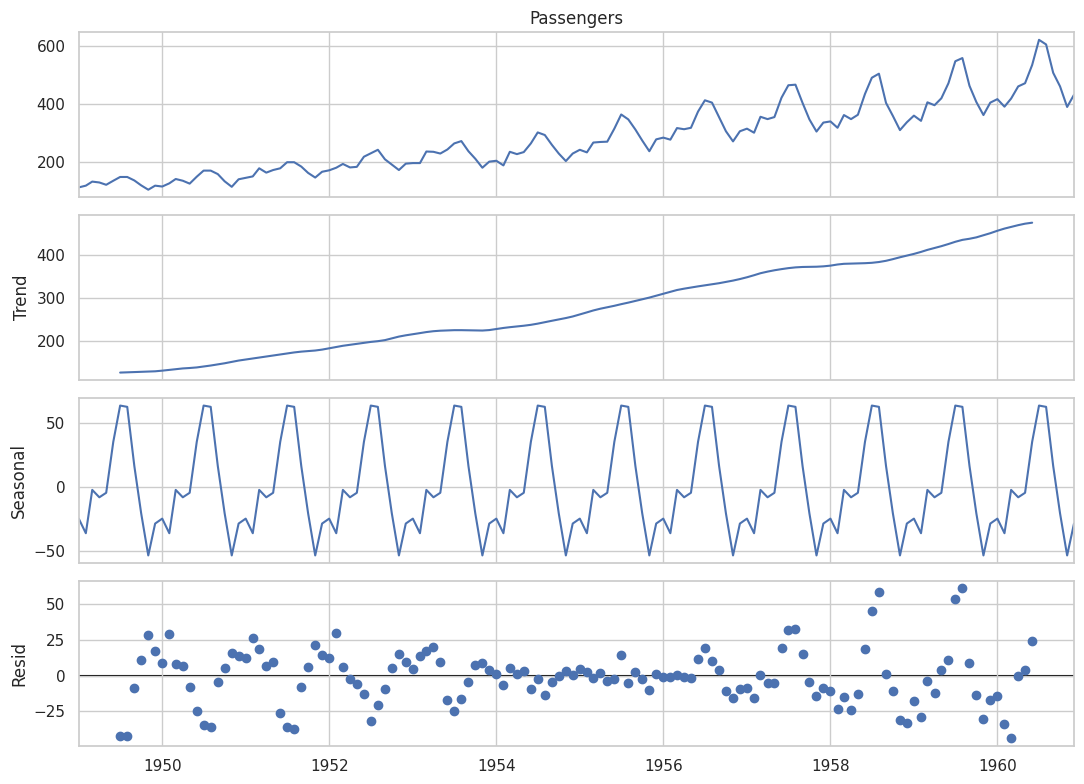

In [128]:
dec = seasonal_decompose(ts, model="additive", period=12)
fig = dec.plot(); fig.set_size_inches(11, 8)
save_fig("A2_decomposition", fig)

### A.4 ACF and PACF (QP6 Q8)

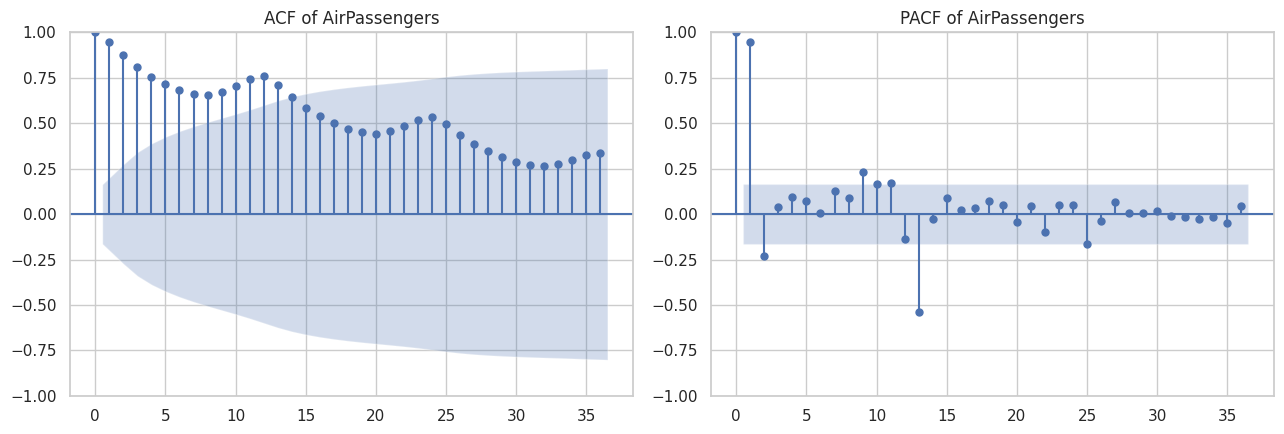

In [129]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_acf(ts, lags=36, ax=axes[0], title="ACF of AirPassengers")
plot_pacf(ts, lags=36, ax=axes[1], title="PACF of AirPassengers")
save_fig("A3_acf_pacf", fig)

### A.5 Fit ARIMA(1,1,1)(0,1,1)[12] and show the summary (QP6 Q9-Q10)

In [130]:
fit = SARIMAX(ts, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(fit.summary())
print(f"AIC = {fit.aic:.2f}  - lower is better; non-seasonal AR/MA terms and the seasonal MA term "
      "capture the trend and yearly cycle.")

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  144
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -507.448
Date:                            Tue, 10 Nov 2026   AIC                           1022.896
Time:                                    10:57:05   BIC                           1034.397
Sample:                                01-01-1949   HQIC                          1027.570
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2436      0.389     -0.626      0.531      -1.006       0.519
ma.L1         -0.0579      0.369   

### A.6 Forecast the next 12 months and plot actual vs forecast (QP6 Q11-Q12)

1961-01-01    445.2
1961-02-01    419.9
1961-03-01    451.5
1961-04-01    488.0
1961-05-01    500.3
1961-06-01    562.4
1961-07-01    648.0
1961-08-01    634.8
1961-09-01    537.0
1961-10-01    489.2
1961-11-01    420.8
1961-12-01    462.8
Freq: MS, Name: predicted_mean, dtype: float64


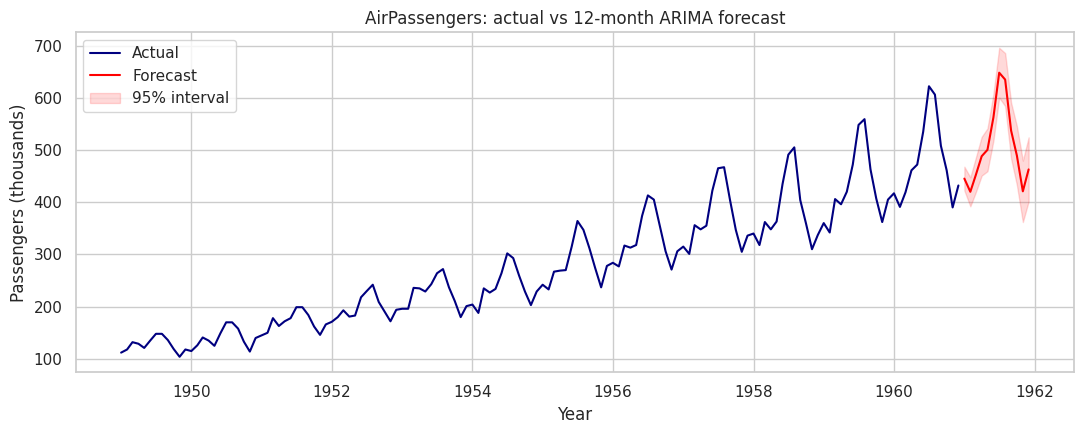

In [131]:
fc = fit.get_forecast(12)
pred, ci = fc.predicted_mean, fc.conf_int()
print(pred.round(1))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(ts, label="Actual", color="navy")
ax.plot(pred, label="Forecast", color="red")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="red", alpha=.15, label="95% interval")
ax.set(title="AirPassengers: actual vs 12-month ARIMA forecast", xlabel="Year", ylabel="Passengers (thousands)")
ax.legend()
save_fig("A4_forecast", fig)

## Done
All figures were also saved in the `eda_output` folder next to this notebook.